# GENIE BPC CRC v2.0-public: feasibility EDA

> **Historical feasibility record — not the active cleaning workflow.** The canonical data-cleaning
> workflow is `notebooks/01_data_cleaning.ipynb`. Counts repeated here are retained only as the
> original evidence used to decide whether the study was feasible.

**Research target:** prognosis from initiation of the first FOLFOX-based systemic
regimen given at or after de novo or recurrent metastatic colorectal cancer
presentation.

This notebook is a model-free feasibility assessment. It:

- audits the complete 59-file release;
- reconstructs the intended cohort and validates FOLFOX exposure;
- validates overall survival (OS) and death-inclusive time to next treatment
  (TTNT-D);
- measures baseline clinical and genomic data availability at the prediction time;
- evaluates institutional internal-external validation support; and
- ends with an explicit feasibility decision and recommended next steps.

Patient identifiers are used internally for linkage but are never displayed.

## 1. Reproducible setup

The GENIE guide uses privacy-preserving time intervals. All cross-table temporal
comparisons below remain on the supplied birth-relative or diagnosis-relative day
scales; no calendar dates are reconstructed.

In [12]:
import hashlib
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from lifelines import KaplanMeierFitter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
warnings.filterwarnings("default")

In [13]:
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "crc_data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "crc_data"
GUIDE_PATH = DATA_DIR / "GENIE BPC CRC v2.0-public Analytic Data Guide v5.pdf"
SYNOPSIS_PATH = DATA_DIR / "BPC_CRC_v2.0-public_variable_synopsis.xlsx"

ANALYTIC_FILES = {
    "patient": "patient_level_dataset.csv",
    "cancer_index": "cancer_level_dataset_index.csv",
    "cancer_non_index": "cancer_level_dataset_non_index.csv",
    "regimens": "regimen_cancer_level_dataset.csv",
    "pathology": "pathology_report_level_dataset.csv",
    "imaging": "imaging_level_dataset.csv",
    "medical_oncology": "med_onc_note_level_dataset.csv",
    "tumor_markers": "tm_level_dataset.csv",
    "cancer_panel_tests": "cancer_panel_test_level_dataset.csv",
}

required_paths = [GUIDE_PATH, SYNOPSIS_PATH, DATA_DIR / "manifest.csv"]
required_paths += [DATA_DIR / file_name for file_name in ANALYTIC_FILES.values()]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(f"Required project inputs are missing: {missing_paths}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Primary analytic tables: {len(ANALYTIC_FILES)}")

Project root: /Users/camilasarmiento/Documents/Data Freelancer/portfolio/CRC
Data directory: /Users/camilasarmiento/Documents/Data Freelancer/portfolio/CRC/crc_data
Primary analytic tables: 9


## 2. Load the primary analytic tables

In [14]:
COMMON_DTYPES = {
    "cohort": "string",
    "record_id": "string",
    "institution": "string",
}

manifest_df = pd.read_csv(DATA_DIR / "manifest.csv", low_memory=False)
tables = {
    table_name: pd.read_csv(
        DATA_DIR / file_name,
        dtype=COMMON_DTYPES,
        low_memory=False,
    )
    for table_name, file_name in ANALYTIC_FILES.items()
}

patient_df = tables["patient"]
cancer_index_df = tables["cancer_index"]
cancer_non_index_df = tables["cancer_non_index"]
regimens_df = tables["regimens"]
pathology_df = tables["pathology"]
imaging_df = tables["imaging"]
medical_oncology_df = tables["medical_oncology"]
tumor_markers_df = tables["tumor_markers"]
cancer_panel_tests_df = tables["cancer_panel_tests"]

dataset_summary = pd.DataFrame(
    [
        {
            "table": table_name,
            "file": ANALYTIC_FILES[table_name],
            "rows": len(frame),
            "columns": frame.shape[1],
            "memory_mb": frame.memory_usage(deep=True).sum() / 1024**2,
            "unique_patients": frame["record_id"].nunique(dropna=True),
        }
        for table_name, frame in tables.items()
    ]
).sort_values("table", ignore_index=True)

assert len(tables) == 9
assert patient_df["record_id"].notna().all()
assert patient_df["record_id"].is_unique

display(dataset_summary)

,table,file,rows,columns,memory_mb,unique_patients
0,cancer_index,cancer_level_dataset_index.csv,1494,142,4.517,1485
1,cancer_non_index,cancer_level_dataset_non_index.csv,336,106,0.949,254
2,cancer_panel_tests,cancer_panel_test_level_dataset.csv,1559,29,0.975,1485
3,imaging,imaging_level_dataset.csv,26260,42,36.598,1475
4,medical_oncology,med_onc_note_level_dataset.csv,28164,12,13.889,1447
5,pathology,pathology_report_level_dataset.csv,7156,320,65.370,1485
6,patient,patient_level_dataset.csv,1485,51,1.449,1485
7,regimens,regimen_cancer_level_dataset.csv,5417,103,10.016,1346
8,tumor_markers,tm_level_dataset.csv,24462,14,9.345,1261


## 3. Complete release inventory and integrity

The release contains 58 manifest payloads plus the manifest itself. The local PDF
has a human-readable filename that differs from the manifest name, so both name-
and hash-based matching are checked.

In [16]:
def calculate_md5(file_path: Path, chunk_size: int = 1024 * 1024) -> str:
    """Calculate an MD5 digest for comparison with the release manifest."""
    digest = hashlib.md5(usedforsecurity=False)
    with file_path.open("rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def classify_release_file(file_name: str) -> str:
    """Assign every local release file to a functional group."""
    documentation_files = {
        "BPC_CRC_v2.0-public_variable_synopsis.xlsx",
        "GENIE BPC CRC v2.0-public Analytic Data Guide v5.pdf",
    }
    portal_clinical_files = {
        "data_clinical_patient.txt",
        "data_clinical_sample.txt",
        "data_clinical_supp_survival.txt",
        "data_clinical_supp_survival_treatment.txt",
    }
    genomic_files = {
        "data_CNA.txt",
        "data_fusions.txt",
        "data_gene_matrix.txt",
        "data_mutations_extended.txt",
        "genie_crc_data_cna_hg19.seg",
        "tmb.tsv",
    }

    if file_name == "manifest.csv":
        return "manifest"
    if file_name in documentation_files:
        return "documentation"
    if file_name in ANALYTIC_FILES.values():
        return "primary analytic table"
    if file_name in portal_clinical_files:
        return "portal clinical/survival"
    if file_name.startswith("data_timeline_"):
        return "timeline"
    if file_name in genomic_files:
        return "genomic data"
    if file_name.startswith("data_gene_panel_"):
        return "gene-panel definition"
    if file_name.startswith("cases_"):
        return "case list"
    if file_name.startswith("meta_") or file_name == "genie_crc_meta_cna_hg19.seg":
        return "metadata"
    return "other"


manifest_by_name = manifest_df.set_index("name", drop=False).to_dict(orient="index")
manifest_by_md5 = manifest_df.set_index("dataFileMD5Hex", drop=False).to_dict(orient="index")

inventory_records = []
for file_path in sorted(DATA_DIR.iterdir()):
    if not file_path.is_file():
        continue

    actual_md5 = calculate_md5(file_path)
    manifest_record = manifest_by_name.get(file_path.name)
    match_method = "name"
    if manifest_record is None:
        manifest_record = manifest_by_md5.get(actual_md5)
        match_method = "md5" if manifest_record is not None else "none"

    expected_name = manifest_record["name"] if manifest_record is not None else pd.NA
    expected_bytes = (
        int(manifest_record["dataFileSizeBytes"]) if manifest_record is not None else pd.NA
    )
    expected_md5 = (
        manifest_record["dataFileMD5Hex"] if manifest_record is not None else pd.NA
    )
    inventory_records.append(
        {
            "file": file_path.name,
            "role": classify_release_file(file_path.name),
            "extension": file_path.suffix.lower(),
            "size_mb": file_path.stat().st_size / 1024**2,
            "manifest_matched": manifest_record is not None,
            "manifest_match_method": match_method,
            "manifest_expected_name": expected_name,
            "size_matches_manifest": file_path.stat().st_size == expected_bytes,
            "hash_matches_manifest": actual_md5 == expected_md5,
        }
    )

file_inventory = pd.DataFrame(inventory_records)
local_hashes = {
    calculate_md5(path) for path in DATA_DIR.iterdir() if path.is_file()
}
manifest_hashes = set(manifest_df["dataFileMD5Hex"])

assert len(file_inventory) == 59
assert len(manifest_df) == 58
assert manifest_hashes.issubset(local_hashes)

inventory_by_role = (
    file_inventory.groupby("role", as_index=False)
    .agg(files=("file", "count"), total_mb=("size_mb", "sum"))
    .sort_values(["files", "role"], ascending=[False, True], ignore_index=True)
)
display(inventory_by_role)

size_matches_manifest = (
    file_inventory["size_matches_manifest"].astype("boolean").fillna(False)
)
hash_matches_manifest = (
    file_inventory["hash_matches_manifest"].astype("boolean").fillna(False)
)
integrity_exceptions = file_inventory.loc[
    (file_inventory["manifest_match_method"] != "name")
    | ~size_matches_manifest
    | ~hash_matches_manifest,
    [
        "file",
        "role",
        "manifest_match_method",
        "manifest_expected_name",
        "size_matches_manifest",
        "hash_matches_manifest",
    ],
]
display(integrity_exceptions)

,role,files,total_mb
0,metadata,16,0.003
1,primary analytic table,9,31.469
2,gene-panel definition,8,0.016
3,timeline,8,11.416
4,genomic data,6,13.174
5,case list,5,0.190
6,portal clinical/survival,4,0.962
7,documentation,2,1.321
8,manifest,1,0.016


,file,role,manifest_match_method,manifest_expected_name,size_matches_manifest,hash_matches_manifest
1,GENIE BPC CRC v2.0-public Analytic Data Guide v5.pdf,documentation,md5,BPC_CRC_v2.0-public_Analytic_Data_Guide.pdf,True,True
37,manifest.csv,manifest,none,<NA>,<NA>,<NA>


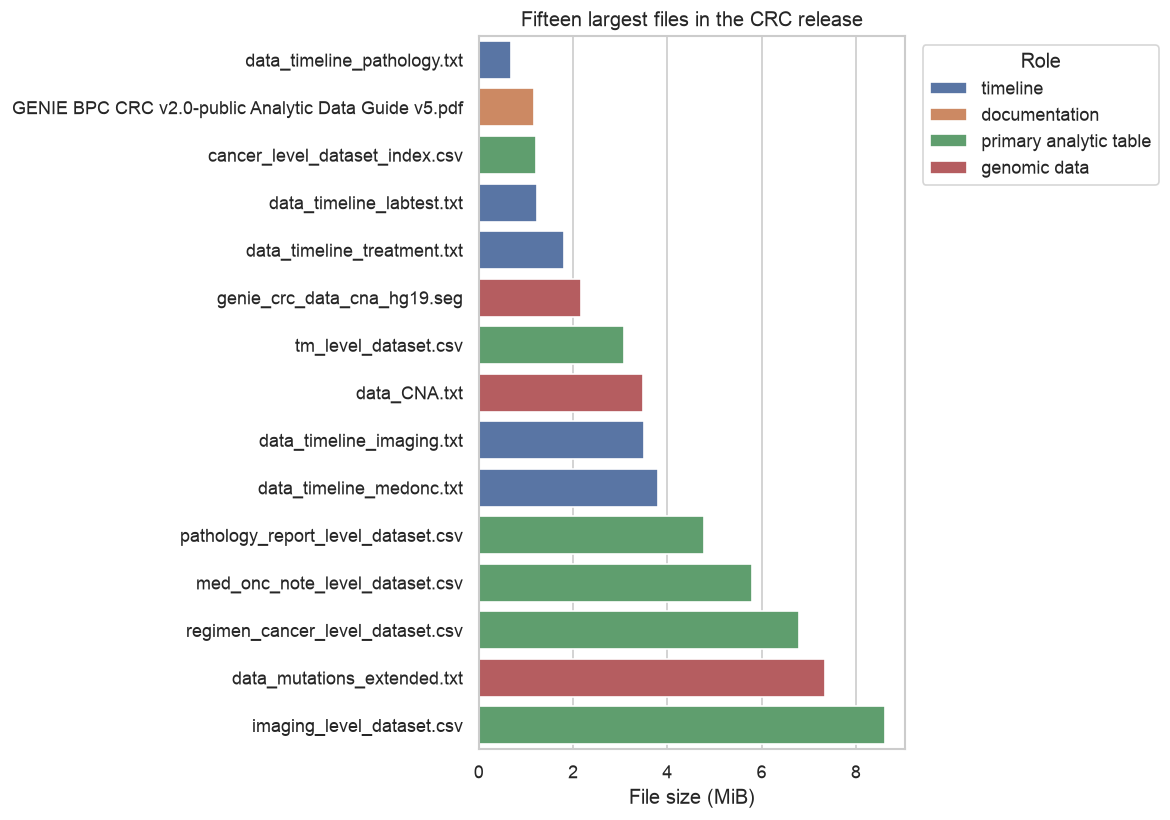

In [17]:
largest_files = file_inventory.nlargest(15, "size_mb").sort_values("size_mb")
figure, axis = plt.subplots(figsize=(10, 7))
sns.barplot(data=largest_files, x="size_mb", y="file", hue="role", ax=axis)
axis.set(
    title="Fifteen largest files in the CRC release",
    xlabel="File size (MiB)",
    ylabel="",
)
axis.legend(title="Role", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 4. Schema, grain, and linkage audit

In [18]:
CANDIDATE_KEYS = {
    "patient": ["record_id"],
    "cancer_index": ["record_id", "ca_seq"],
    "cancer_non_index": ["record_id", "ca_seq"],
    "regimens": ["record_id", "regimen_number", "ca_seq"],
    "pathology": ["record_id", "path_proc_number", "path_rep_number"],
    "imaging": ["record_id", "scan_number"],
    "medical_oncology": ["record_id", "md_visit_number"],
    "tumor_markers": ["record_id", "tm_number", "tm_type"],
    "cancer_panel_tests": ["record_id", "cpt_number", "ca_seq"],
}

schema_records = []
all_missing_records = []
for table_name, frame in tables.items():
    key_columns = CANDIDATE_KEYS[table_name]
    complete_key = frame[key_columns].notna().all(axis=1)
    duplicate_complete_key = frame.loc[complete_key, key_columns].duplicated(keep=False)
    all_missing_columns = frame.columns[frame.isna().all()].tolist()
    schema_records.append(
        {
            "table": table_name,
            "rows": len(frame),
            "columns": frame.shape[1],
            "full_row_duplicates": int(frame.duplicated().sum()),
            "duplicate_column_names": int(frame.columns.duplicated().sum()),
            "all_missing_columns": len(all_missing_columns),
            "candidate_key": " + ".join(key_columns),
            "rows_missing_key_component": int((~complete_key).sum()),
            "rows_in_duplicate_complete_keys": int(duplicate_complete_key.sum()),
        }
    )
    all_missing_records.extend(
        {"table": table_name, "column": column_name}
        for column_name in all_missing_columns
    )

schema_audit = pd.DataFrame(schema_records).sort_values("table", ignore_index=True)
all_missing_columns_df = pd.DataFrame(
    all_missing_records,
    columns=["table", "column"],
)
display(schema_audit)
display(all_missing_columns_df)

,table,rows,columns,full_row_duplicates,duplicate_column_names,all_missing_columns,candidate_key,rows_missing_key_component,rows_in_duplicate_complete_keys
0,cancer_index,1494,142,0,0,2,record_id + ca_seq,0,0
1,cancer_non_index,336,106,0,0,17,record_id + ca_seq,0,0
2,cancer_panel_tests,1559,29,0,0,0,record_id + cpt_number + ca_seq,0,0
3,imaging,26260,42,0,0,3,record_id + scan_number,0,0
4,medical_oncology,28164,12,0,0,0,record_id + md_visit_number,0,0
5,pathology,7156,320,0,0,39,record_id + path_proc_number + path_rep_number,0,0
6,patient,1485,51,0,0,0,record_id,0,0
7,regimens,5417,103,0,0,0,record_id + regimen_number + ca_seq,0,0
8,tumor_markers,24462,14,0,0,0,record_id + tm_number + tm_type,0,0


,table,column
0,cancer_index,ca_path_n3_det
1,cancer_index,ca_clinical_n3_det
2,cancer_non_index,ca_path_n2_det
3,cancer_non_index,ca_path_n3_det
4,cancer_non_index,ca_clin_t4_det
5,cancer_non_index,ca_clin_n1_det
6,cancer_non_index,ca_clinical_n3_det
7,cancer_non_index,ca_first_dmets4
8,cancer_non_index,ca_first_dmets5
9,cancer_non_index,ca_first_dmets6


In [20]:
patient_ids = set(patient_df["record_id"])
institution_lookup = patient_df.set_index("record_id")["institution"]
linkage_records = []

for table_name, frame in tables.items():
    invalid_patient_ids = int((~frame["record_id"].isin(patient_ids)).sum())
    expected_institution = frame["record_id"].map(institution_lookup)
    institution_disagreements = int(
        (
            frame["institution"].notna()
            & expected_institution.notna()
            & frame["institution"].ne(expected_institution)
        ).sum()
    )
    linkage_records.append(
        {
            "table": table_name,
            "rows": len(frame),
            "patient_ids_not_in_patient_table": invalid_patient_ids,
            "institution_disagreements": institution_disagreements,
        }
    )

linkage_audit = pd.DataFrame(linkage_records)
assert linkage_audit["patient_ids_not_in_patient_table"].sum() == 0
assert linkage_audit["institution_disagreements"].sum() == 0
display(linkage_audit)

,table,rows,patient_ids_not_in_patient_table,institution_disagreements
0,patient,1485,0,0
1,cancer_index,1494,0,0
2,cancer_non_index,336,0,0
3,regimens,5417,0,0
4,pathology,7156,0,0
5,imaging,26260,0,0
6,medical_oncology,28164,0,0
7,tumor_markers,24462,0,0
8,cancer_panel_tests,1559,0,0


In [23]:
regimens_df

,cohort,record_id,institution,ca_seq,regimen_number,regimen_number_within_cancer,redcap_ca_index,drugs_num,drugs_inst,drugs_firstinst,drugs_ct_yn,drugs_dc_ynu,regimen_drugs,drugs_drug_1,drugs_drug_2,drugs_drug_3,drugs_drug_4,drugs_drug_5,drugs_admin,drugs_startdt_int_1,drugs_startdt_int_2,drugs_startdt_int_3,drugs_startdt_int_4,drugs_startdt_int_5,dx_drug_start_int_1,dx_drug_start_int_2,dx_drug_start_int_3,dx_drug_start_int_4,dx_drug_start_int_5,dx_drug_start_int_mos_1,dx_drug_start_int_mos_2,dx_drug_start_int_mos_3,dx_drug_start_int_mos_4,dx_drug_start_int_mos_5,dx_drug_end_int_1,dx_drug_end_int_2,dx_drug_end_int_3,dx_drug_end_int_4,dx_drug_end_int_5,dx_drug_end_int_mos_1,dx_drug_end_int_mos_2,dx_drug_end_int_mos_3,dx_drug_end_int_mos_4,dx_drug_end_int_mos_5,dx_drug_end_or_lastadm_int_1,dx_drug_end_or_lastadm_int_2,dx_drug_end_or_lastadm_int_3,dx_drug_end_or_lastadm_int_4,dx_drug_end_or_lastadm_int_5,dx_reg_start_int,dx_reg_start_int_mos,dx_reg_start_int_yrs,dx_reg_end_any_int,dx_reg_end_any_int_mos,dx_reg_end_any_int_yrs,dx_reg_end_all_int,dx_reg_end_all_int_mos,dx_reg_end_all_int_yrs,os_d_status,tt_os_d1_days,tt_os_d2_days,tt_os_d3_days,tt_os_d4_days,tt_os_d5_days,tt_os_d1_mos,tt_os_d2_mos,tt_os_d3_mos,tt_os_d4_mos,tt_os_d5_mos,tt_os_d1_yrs,tt_os_d2_yrs,tt_os_d3_yrs,tt_os_d4_yrs,tt_os_d5_yrs,os_g_status,tt_os_g_days,tt_os_g_mos,tt_os_g_yrs,pfs_i_g_status,tt_pfs_i_g_days,tt_pfs_i_g_mos,tt_pfs_i_g_yrs,pfs_m_g_status,tt_pfs_m_g_days,tt_pfs_m_g_mos,tt_pfs_m_g_yrs,pfs_i_or_m_g_status,tt_pfs_i_or_m_g_days,tt_pfs_i_or_m_g_mos,tt_pfs_i_or_m_g_yrs,pfs_i_and_m_g_status,tt_pfs_i_and_m_g_days,tt_pfs_i_and_m_g_mos,tt_pfs_i_and_m_g_yrs,ttnt_any_ca_status,ttnt_any_ca_days,ttnt_any_ca_mos,ttnt_any_ca_yrs,ttnt_ca_seq_status,ttnt_ca_seq_days,ttnt_ca_seq_mos,ttnt_ca_seq_yrs,release_version
0,CRC,GENIE-DFCI-000048,DFCI,0,1,1,Yes,2,At the internal/native institution only,NaN,No,Yes,"Fluorouracil, Leucovorin Calcium","Fluorouracil(5FU,5Fluorouracil,5Fluracil,AccuSite,Adrucil,Carac,Fluouracil,Flurablastin,Fluracedyl,Fluracil,Fluril,Fluroblastin,Ribofluo...","Leucovorin Calcium(Calfolex,Calinat,Cehafolin,Citofolin,Citrec,Citrovorum Factor,Cromatonbic Folinico,Dalisol,Disintox,Divical,Ecofol,Em...",NaN,NaN,NaN,NaN,21765,"21,765.000",NaN,NaN,NaN,51,51.000,NaN,NaN,NaN,1.678,1.678,NaN,NaN,NaN,205.000,205.000,NaN,NaN,NaN,6.743,6.743,NaN,NaN,NaN,205.000,205.000,NaN,NaN,NaN,51,1.678,0.140,205.000,6.743,0.561,205.000,6.743,0.561,0,273,273.000,NaN,NaN,NaN,8.980,8.980,NaN,NaN,NaN,0.747,0.747,NaN,NaN,NaN,0,273,8.980,0.747,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,273,8.980,0.747,0,273,8.980,0.747,2.0-public
1,CRC,GENIE-DFCI-000147,DFCI,0,1,1,Yes,1,At external institution only,NaN,No,Yes,Capecitabine,"Capecitabine(Ro091978 000,Xeloda)",NaN,NaN,NaN,NaN,NaN,18545,NaN,NaN,NaN,NaN,24,NaN,NaN,NaN,NaN,0.789,NaN,NaN,NaN,NaN,73.000,NaN,NaN,NaN,NaN,2.401,NaN,NaN,NaN,NaN,73.000,NaN,NaN,NaN,NaN,24,0.789,0.066,73.000,2.401,0.200,73.000,2.401,0.200,1,1211,NaN,NaN,NaN,NaN,39.836,NaN,NaN,NaN,NaN,3.316,NaN,NaN,NaN,NaN,1,1211,39.836,3.316,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,181,5.954,0.496,1,181,5.954,0.496,2.0-public
2,CRC,GENIE-DFCI-000147,DFCI,0,2,2,Yes,2,At external institution only,NaN,No,Yes,"Capecitabine, Oxaliplatin","Capecitabine(Ro091978 000,Xeloda)","Oxaliplatin(1OHP,Ai Heng,DACPLAT,Dacotin,ELOXATIN,Eloxatine,JM83)",NaN,NaN,NaN,NaN,18726,"18,726.000",NaN,NaN,NaN,205,205.000,NaN,NaN,NaN,6.743,6.743,NaN,NaN,NaN,309.000,309.000,NaN,NaN,NaN,10.164,10.164,NaN,NaN,NaN,309.000,309.000,NaN,NaN,NaN,205,6.743,0.561,309.000,10.164,0.846,309.000,10.164,0.846,1,1030,"1,030.000",NaN,NaN,NaN,33.882,33.882,NaN,NaN,NaN,2.820,2.820,NaN,NaN,NaN,1,1030,33.882,2.820,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,275,9.046,0.753,1,275,9.046,0.753,2.0-public
3,CRC,GENIE-DFCI-000147,DFCI,0,3,3,Yes,4,At external institution only,NaN,No,Yes,"Bevacizumab, Fluorouracil, Irinotecan Hydrochloride, Leucovorin Calcium","Fluo

In [24]:
all_cancer_keys = pd.concat(
    [
        cancer_index_df[["record_id", "ca_seq"]],
        cancer_non_index_df[["record_id", "ca_seq"]],
    ],
    ignore_index=True,
).drop_duplicates()

known_regimen_cancer = regimens_df.dropna(subset=["ca_seq"])[["record_id", "ca_seq"]]
regimen_cancer_link = known_regimen_cancer.merge(
    all_cancer_keys.assign(cancer_key_found=True),
    on=["record_id", "ca_seq"],
    how="left",
)
cpt_cancer_link = cancer_panel_tests_df.dropna(subset=["ca_seq"])[
    ["record_id", "ca_seq"]
].merge(
    cancer_index_df[["record_id", "ca_seq"]].assign(index_key_found=True),
    on=["record_id", "ca_seq"],
    how="left",
)

physical_regimen_counts = (
    regimens_df.groupby(["record_id", "regimen_number"], dropna=False)
    .agg(rows=("ca_seq", "size"), associated_cancers=("ca_seq", "nunique"))
    .reset_index()
)

cross_table_linkage = pd.DataFrame(
    [
        {
            "check": "Regimen rows with known cancer association linked to a cancer row",
            "eligible_rows": len(regimen_cancer_link),
            "matched_rows": int(regimen_cancer_link["cancer_key_found"].fillna(False).sum()),
        },
        {
            "check": "Cancer-panel rows with known association linked to an index cancer",
            "eligible_rows": len(cpt_cancer_link),
            "matched_rows": int(cpt_cancer_link["index_key_found"].fillna(False).sum()),
        },
        {
            "check": "Physical regimens associated with more than one cancer",
            "eligible_rows": len(physical_regimen_counts),
            "matched_rows": int((physical_regimen_counts["associated_cancers"] > 1).sum()),
        },
    ]
)
cross_table_linkage["percent"] = (
    100 * cross_table_linkage["matched_rows"] / cross_table_linkage["eligible_rows"]
)
display(cross_table_linkage)

,check,eligible_rows,matched_rows,percent
0,Regimen rows with known cancer association linked to a cancer row,5417,5417,100.000
1,Cancer-panel rows with known association linked to an index cancer,1559,1559,100.000
2,Physical regimens associated with more than one cancer,5318,93,1.749


In [25]:
variable_synopsis = pd.read_excel(SYNOPSIS_PATH, sheet_name="Variable Synopsis")
synopsis_summary = (
    variable_synopsis.groupby("Dataset", as_index=False)
    .agg(documented_variables=("Variable Name", "nunique"))
    .sort_values("Dataset", ignore_index=True)
)

analytic_schema_sets = {
    "Patient-level dataset": set(patient_df.columns),
    "Cancer diagnosis dataset": set(cancer_index_df.columns)
    | set(cancer_non_index_df.columns),
    "Cancer-directed regimen dataset": set(regimens_df.columns),
    "PRISSMM Pathology level dataset": set(pathology_df.columns),
    "PRISSMM Imaging level dataset": set(imaging_df.columns),
    "PRISSMM Medical Oncologist Assessment level dataset": set(
        medical_oncology_df.columns
    ),
    "PRISSMM Tumor Marker level dataset": set(tumor_markers_df.columns),
    "Cancer panel test level dataset": set(cancer_panel_tests_df.columns),
}

synopsis_reconciliation = []
for dataset_name, documented_group in variable_synopsis.groupby("Dataset"):
    documented = set(documented_group["Variable Name"].dropna())
    observed = analytic_schema_sets[dataset_name]
    synopsis_reconciliation.append(
        {
            "dataset": dataset_name,
            "documented_variables": len(documented),
            "observed_union_variables": len(observed),
            "documented_not_observed": ", ".join(sorted(documented - observed)),
            "observed_not_documented": ", ".join(sorted(observed - documented)),
        }
    )

print(f"Documented variables in synopsis: {len(variable_synopsis):,}")
display(synopsis_summary)
display(pd.DataFrame(synopsis_reconciliation))

Documented variables in synopsis: 740


,Dataset,documented_variables
0,Cancer diagnosis dataset,168
1,Cancer panel test level dataset,29
2,Cancer-directed regimen dataset,103
3,PRISSMM Imaging level dataset,42
4,PRISSMM Medical Oncologist Assessment level dataset,12
5,PRISSMM Pathology level dataset,320
6,PRISSMM Tumor Marker level dataset,15
7,Patient-level dataset,51


,dataset,documented_variables,observed_union_variables,documented_not_observed,observed_not_documented
0,Cancer diagnosis dataset,168,168,,
1,Cancer panel test level dataset,29,29,,
2,Cancer-directed regimen dataset,103,103,,
3,PRISSMM Imaging level dataset,42,42,,
4,PRISSMM Medical Oncologist Assessment level dataset,12,12,,
5,PRISSMM Pathology level dataset,320,320,,
6,PRISSMM Tumor Marker level dataset,15,14,tm_result_out_of_range,
7,Patient-level dataset,51,51,,


In [26]:
institution_coverage_records = []
for table_name, frame in tables.items():
    coverage = (
        frame.groupby("institution", dropna=False)
        .agg(rows=("record_id", "size"), unique_patients=("record_id", "nunique"))
        .reset_index()
    )
    coverage.insert(0, "table", table_name)
    institution_coverage_records.append(coverage)

institution_coverage = pd.concat(institution_coverage_records, ignore_index=True)
patient_coverage_by_institution = (
    institution_coverage.pivot(
        index="table",
        columns="institution",
        values="unique_patients",
    )
    .fillna(0)
    .astype(int)
)
display(patient_coverage_by_institution)

institution,DFCI,MSK,VICC
table,,,
cancer_index,564,696,225
cancer_non_index,98,127,29
cancer_panel_tests,564,696,225
imaging,560,691,224
medical_oncology,550,675,222
pathology,564,696,225
patient,564,696,225
regimens,491,642,213
tumor_markers,409,666,186


## 5. Time-axis audit and metastatic presentation

Guide rules used here:

- Stage IV at diagnosis is de novo metastatic disease.
- For Stage I-III cancers, `dx_to_dmets_days` supplies the interval to subsequent
  distant metastasis when `dmets_stage_i_iii == 1`.
- Absolute treatment component times are intervals from date of birth.
- A regimen may appear on multiple rows when associated with multiple cancers.

In [27]:
index_cancers = cancer_index_df.copy()
index_cancers["is_de_novo"] = index_cancers["stage_dx_iv"].eq("Stage IV")
index_cancers["is_recurrent"] = (
    index_cancers["stage_dx_iv"].eq("Stage I-III")
    & index_cancers["dmets_stage_i_iii"].eq(1)
)
index_cancers["metastatic_presentation"] = np.select(
    [index_cancers["is_de_novo"], index_cancers["is_recurrent"]],
    ["De novo Stage IV", "Recurrent/metachronous"],
    default="Not documented as metastatic",
)
index_cancers["advanced_origin_day"] = np.select(
    [index_cancers["is_de_novo"], index_cancers["is_recurrent"]],
    [
        index_cancers["dob_ca_dx_days"],
        index_cancers["dob_ca_dx_days"] + index_cancers["dx_to_dmets_days"],
    ],
    default=np.nan,
)

advanced_cancers = index_cancers.loc[
    index_cancers["advanced_origin_day"].notna()
].copy()

advanced_summary = (
    advanced_cancers.groupby(["institution", "metastatic_presentation"])
    .agg(cancers=("ca_seq", "size"), patients=("record_id", "nunique"))
    .reset_index()
)
print(
    f"Advanced index cancers: {len(advanced_cancers):,}; "
    f"patients: {advanced_cancers['record_id'].nunique():,}"
)
display(advanced_summary)

Advanced index cancers: 1,285; patients: 1,282


,institution,metastatic_presentation,cancers,patients
0,DFCI,De novo Stage IV,219,219
1,DFCI,Recurrent/metachronous,246,246
2,MSK,De novo Stage IV,348,348
3,MSK,Recurrent/metachronous,249,249
4,VICC,De novo Stage IV,137,134
5,VICC,Recurrent/metachronous,86,86


In [28]:
DRUG_COLUMNS = [f"drugs_drug_{number}" for number in range(1, 6)]
DRUG_START_COLUMNS = [f"drugs_startdt_int_{number}" for number in range(1, 6)]

regimens = regimens_df.copy()
regimens["regimen_origin_day"] = regimens[DRUG_START_COLUMNS].min(axis=1)
regimens["derived_dx_reg_start"] = (
    regimens["regimen_origin_day"]
    - regimens.merge(
        pd.concat(
            [
                cancer_index_df[["record_id", "ca_seq", "dob_ca_dx_days"]],
                cancer_non_index_df[["record_id", "ca_seq", "dob_ca_dx_days"]],
            ],
            ignore_index=True,
        ).drop_duplicates(["record_id", "ca_seq"]),
        on=["record_id", "ca_seq"],
        how="left",
    )["dob_ca_dx_days"].to_numpy()
)

time_axis_audit = regimens.loc[
    regimens["derived_dx_reg_start"].notna() & regimens["dx_reg_start_int"].notna()
].copy()
time_axis_audit["start_difference_days"] = (
    time_axis_audit["derived_dx_reg_start"] - time_axis_audit["dx_reg_start_int"]
)

time_axis_summary = pd.DataFrame(
    [
        {
            "check": "Regimen rows missing all five absolute component starts",
            "rows": int(regimens["regimen_origin_day"].isna().sum()),
        },
        {
            "check": "Rows eligible for absolute-vs-diagnosis-relative comparison",
            "rows": len(time_axis_audit),
        },
        {
            "check": "Rows where reconstructed and supplied regimen start differ",
            "rows": int(time_axis_audit["start_difference_days"].ne(0).sum()),
        },
        {
            "check": "Recurrent metastatic cancers missing dx_to_dmets_days",
            "rows": int(
                index_cancers.loc[
                    index_cancers["is_recurrent"], "dx_to_dmets_days"
                ].isna().sum()
            ),
        },
    ]
)
display(time_axis_summary)

,check,rows
0,Regimen rows missing all five absolute component starts,0
1,Rows eligible for absolute-vs-diagnosis-relative comparison,5417
2,Rows where reconstructed and supplied regimen start differ,0
3,Recurrent metastatic cancers missing dx_to_dmets_days,0


## 6. First post-metastatic regimen and FOLFOX phenotype

In [ ]:
candidate_regimens = regimens.merge(
    advanced_cancers[
        [
            "record_id",
            "ca_seq",
            "advanced_origin_day",
            "metastatic_presentation",
            "age_dx",
            "crc_type",
            "ca_d_site",
            "ca_grade",
            "dmets_abdomen",
            "dmets_bone",
            "dmets_brain",
            "dmets_liver",
            "dmets_pelvis",
            "dmets_thorax",
        ]
    ],
    on=["record_id", "ca_seq"],
    how="inner",
    validate="many_to_one",
)
candidate_regimens["is_post_metastatic"] = (
    candidate_regimens["regimen_origin_day"].notna()
    & candidate_regimens["advanced_origin_day"].notna()
    & (
        candidate_regimens["regimen_origin_day"]
        >= candidate_regimens["advanced_origin_day"]
    )
)
post_metastatic_regimens = candidate_regimens.loc[
    candidate_regimens["is_post_metastatic"]
].copy()

post_metastatic_regimens["advanced_associations_per_physical_regimen"] = (
    post_metastatic_regimens.groupby(["record_id", "regimen_number"])[
        "ca_seq"
    ].transform("nunique")
)
first_post_metastatic = (
    post_metastatic_regimens.sort_values(
        ["record_id", "regimen_origin_day", "regimen_number", "ca_seq"]
    )
    .drop_duplicates(["record_id", "regimen_number"])
    .drop_duplicates("record_id")
    .copy()
)
first_post_metastatic["age_at_regimen"] = (
    first_post_metastatic["regimen_origin_day"] / 365.25
)


def generic_drug_name(value: object) -> str:
    """Return the generic component before the synonym list."""
    if pd.isna(value):
        return ""
    return str(value).split("(", maxsplit=1)[0].strip().casefold()


first_post_metastatic["drug_set"] = first_post_metastatic[DRUG_COLUMNS].apply(
    lambda row: frozenset(
        generic_drug_name(value)
        for value in row
        if generic_drug_name(value)
    ),
    axis=1,
)

FOLFOX_BACKBONE = frozenset(
    {"fluorouracil", "leucovorin calcium", "oxaliplatin"}
)
ALLOWED_BIOLOGICS = frozenset(
    {
        "aflibercept",
        "atezolizumab",
        "bevacizumab",
        "cetuximab",
        "nivolumab",
        "panitumumab",
        "pembrolizumab",
        "ramucirumab",
        "ziv-aflibercept",
    }
)


def contains_drug(drug_set: frozenset[str], fragment: str) -> bool:
    return any(fragment in drug_name for drug_name in drug_set)


def classify_first_regimen(drug_set: frozenset[str]) -> str:
    has_backbone = FOLFOX_BACKBONE.issubset(drug_set)
    has_capecitabine = contains_drug(drug_set, "capecitabine")
    has_irinotecan = contains_drug(drug_set, "irinotecan")
    extras = drug_set - FOLFOX_BACKBONE

    if has_backbone and has_irinotecan:
        return "FOLFOXIRI (excluded)"
    if has_capecitabine and contains_drug(drug_set, "oxaliplatin"):
        return "CAPOX/XELOX (excluded)"
    if has_backbone and not extras:
        return "Exact FOLFOX"
    if has_backbone and not has_capecitabine and not has_irinotecan:
        if extras.issubset(ALLOWED_BIOLOGICS):
            return "FOLFOX plus biologic"
        return "FOLFOX plus non-biologic agent"
    return "Other first regimen"


first_post_metastatic["regimen_class"] = first_post_metastatic["drug_set"].map(
    classify_first_regimen
)
first_post_metastatic["broad_folfox"] = first_post_metastatic["drug_set"].map(
    lambda drugs: (
        FOLFOX_BACKBONE.issubset(drugs)
        and not contains_drug(drugs, "capecitabine")
        and not contains_drug(drugs, "irinotecan")
    )
)
first_post_metastatic["primary_folfox"] = first_post_metastatic[
    "regimen_class"
].isin(["Exact FOLFOX", "FOLFOX plus biologic"])
first_post_metastatic["adult"] = first_post_metastatic["age_at_regimen"].ge(18)

phenotype_summary = (
    first_post_metastatic.groupby("regimen_class", as_index=False)
    .agg(patients=("record_id", "nunique"))
    .sort_values("patients", ascending=False, ignore_index=True)
)
display(phenotype_summary)

,regimen_class,patients
0,Exact FOLFOX,439
1,Other first regimen,395
2,FOLFOX plus biologic,239
3,CAPOX/XELOX (excluded),41
4,FOLFOXIRI (excluded),35
5,FOLFOX plus non-biologic agent,1


In [30]:
physical_regimens = (
    regimens.sort_values(["record_id", "regimen_number", "regimen_origin_day"])
    .drop_duplicates(["record_id", "regimen_number"])
    .copy()
)
physical_regimens["has_oxaliplatin"] = physical_regimens[DRUG_COLUMNS].apply(
    lambda row: any(
        "oxaliplatin" in generic_drug_name(value)
        for value in row
        if pd.notna(value)
    ),
    axis=1,
)

primary_cohort = first_post_metastatic.loc[
    first_post_metastatic["primary_folfox"] & first_post_metastatic["adult"]
].copy()

prior_oxaliplatin_pairs = primary_cohort[
    ["record_id", "regimen_origin_day"]
].merge(
    physical_regimens[
        ["record_id", "regimen_origin_day", "has_oxaliplatin"]
    ],
    on="record_id",
    suffixes=("_folfox", "_other"),
    how="left",
)
prior_oxaliplatin_pairs["prior_oxaliplatin"] = (
    prior_oxaliplatin_pairs["has_oxaliplatin"]
    & (
        prior_oxaliplatin_pairs["regimen_origin_day_other"]
        < prior_oxaliplatin_pairs["regimen_origin_day_folfox"]
    )
)
prior_oxaliplatin = prior_oxaliplatin_pairs.groupby("record_id")[
    "prior_oxaliplatin"
].any()
primary_cohort["prior_oxaliplatin"] = primary_cohort["record_id"].map(
    prior_oxaliplatin
).fillna(False)
primary_cohort["biologic_with_folfox"] = primary_cohort["regimen_class"].eq(
    "FOLFOX plus biologic"
)

patient_baseline_columns = [
    "record_id",
    "naaccr_sex_code",
    "race_ethnicity",
    "hybrid_death_int",
    "dob_lastalive_int",
]
primary_cohort = primary_cohort.merge(
    patient_df[patient_baseline_columns],
    on="record_id",
    how="left",
    validate="one_to_one",
)

assert primary_cohort["record_id"].is_unique
assert primary_cohort["age_at_regimen"].ge(18).all()
assert primary_cohort["regimen_origin_day"].ge(
    primary_cohort["advanced_origin_day"]
).all()
assert primary_cohort["drug_set"].map(FOLFOX_BACKBONE.issubset).all()
assert ~primary_cohort["drug_set"].map(
    lambda drugs: contains_drug(drugs, "capecitabine")
    or contains_drug(drugs, "irinotecan")
).any()

cohort_flow = pd.DataFrame(
    [
        {
            "step": "All release patients",
            "patients": patient_df["record_id"].nunique(),
        },
        {
            "step": "Documented advanced index CRC",
            "patients": advanced_cancers["record_id"].nunique(),
        },
        {
            "step": "At least one linked post-metastatic regimen",
            "patients": post_metastatic_regimens["record_id"].nunique(),
        },
        {
            "step": "First regimen contains FOLFOX backbone",
            "patients": int(first_post_metastatic["broad_folfox"].sum()),
        },
        {
            "step": "Primary FOLFOX definition and adult",
            "patients": len(primary_cohort),
        },
        {
            "step": "Complete regimen-level OS",
            "patients": int(
                primary_cohort[["os_g_status", "tt_os_g_days"]]
                .notna()
                .all(axis=1)
                .sum()
            ),
        },
    ]
)
display(cohort_flow)

,step,patients
0,All release patients,1485
1,Documented advanced index CRC,1282
2,At least one linked post-metastatic regimen,1150
3,First regimen contains FOLFOX backbone,679
4,Primary FOLFOX definition and adult,678
5,Complete regimen-level OS,678


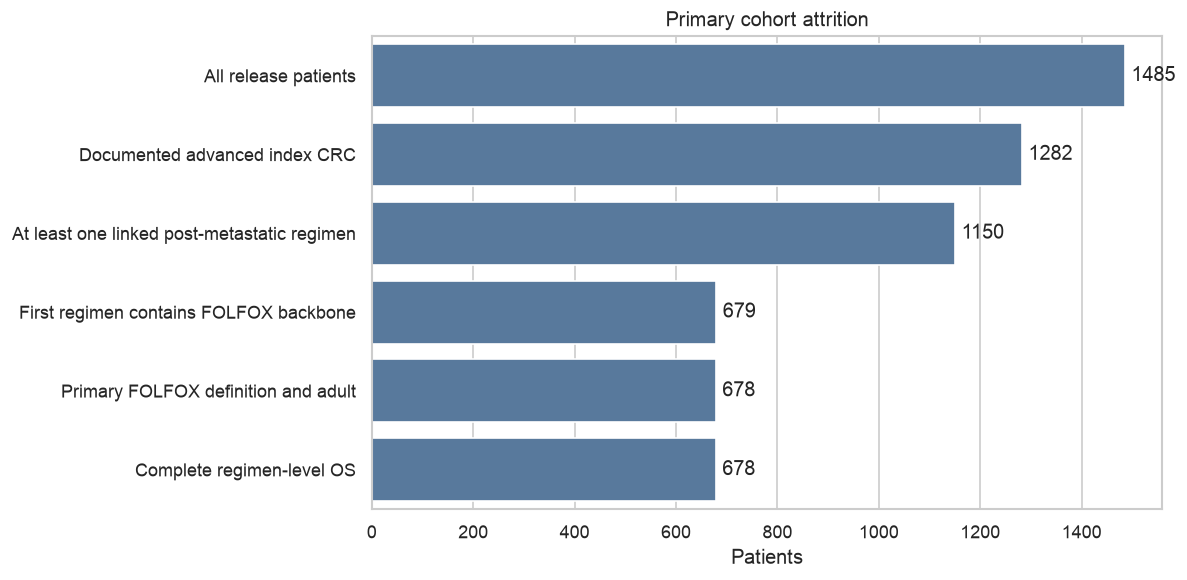

In [31]:
figure, axis = plt.subplots(figsize=(10, 5))
sns.barplot(data=cohort_flow, x="patients", y="step", color="#4C78A8", ax=axis)
axis.set(title="Primary cohort attrition", xlabel="Patients", ylabel="")
for container in axis.containers:
    axis.bar_label(container, padding=4)
plt.tight_layout()
plt.show()

In [32]:
cohort_characteristics = pd.DataFrame(
    [
        {
            "characteristic": "Patients",
            "value": len(primary_cohort),
        },
        {
            "characteristic": "De novo Stage IV",
            "value": int(
                primary_cohort["metastatic_presentation"]
                .eq("De novo Stage IV")
                .sum()
            ),
        },
        {
            "characteristic": "Recurrent/metachronous",
            "value": int(
                primary_cohort["metastatic_presentation"]
                .eq("Recurrent/metachronous")
                .sum()
            ),
        },
        {
            "characteristic": "FOLFOX plus biologic",
            "value": int(primary_cohort["biologic_with_folfox"].sum()),
        },
        {
            "characteristic": "Previous oxaliplatin",
            "value": int(primary_cohort["prior_oxaliplatin"].sum()),
        },
        {
            "characteristic": "Physical regimens with multiple advanced associations",
            "value": int(
                (
                    primary_cohort["advanced_associations_per_physical_regimen"]
                    > 1
                ).sum()
            ),
        },
    ]
)
display(cohort_characteristics)

,characteristic,value
0,Patients,678
1,De novo Stage IV,487
2,Recurrent/metachronous,191
3,FOLFOX plus biologic,239
4,Previous oxaliplatin,19
5,Physical regimens with multiple advanced associations,2


## 7. Primary endpoint: OS from FOLFOX initiation

The guide defines `os_g_status` as death versus censoring and `tt_os_g_days` as
time from regimen start to death or last known alive. These supplied fields are
recomputed below on the same privacy-preserving day scale.

In [33]:
primary_cohort["expected_os_days"] = np.where(
    primary_cohort["os_g_status"].eq(1),
    primary_cohort["hybrid_death_int"] - primary_cohort["regimen_origin_day"],
    primary_cohort["dob_lastalive_int"] - primary_cohort["regimen_origin_day"],
)
primary_cohort["os_difference_days"] = (
    primary_cohort["tt_os_g_days"] - primary_cohort["expected_os_days"]
)

os_validation = pd.DataFrame(
    [
        {
            "check": "Missing OS status",
            "patients": int(primary_cohort["os_g_status"].isna().sum()),
        },
        {
            "check": "Missing OS time",
            "patients": int(primary_cohort["tt_os_g_days"].isna().sum()),
        },
        {
            "check": "Negative OS time",
            "patients": int(primary_cohort["tt_os_g_days"].lt(0).sum()),
        },
        {
            "check": "Zero-day OS",
            "patients": int(primary_cohort["tt_os_g_days"].eq(0).sum()),
        },
        {
            "check": "Supplied OS differs from recomputed OS",
            "patients": int(primary_cohort["os_difference_days"].ne(0).sum()),
        },
    ]
)
assert primary_cohort["os_g_status"].isin([0, 1]).all()
assert primary_cohort["tt_os_g_days"].ge(0).all()
assert primary_cohort["os_difference_days"].eq(0).all()
display(os_validation)

,check,patients
0,Missing OS status,0
1,Missing OS time,0
2,Negative OS time,0
3,Zero-day OS,0
4,Supplied OS differs from recomputed OS,0


In [34]:
os_by_institution = (
    primary_cohort.groupby("institution")
    .agg(
        patients=("record_id", "size"),
        deaths=("os_g_status", "sum"),
        death_percent=("os_g_status", lambda values: 100 * values.mean()),
        median_observed_days=("tt_os_g_days", "median"),
    )
    .reset_index()
)
os_by_presentation = (
    primary_cohort.groupby("metastatic_presentation")
    .agg(
        patients=("record_id", "size"),
        deaths=("os_g_status", "sum"),
        death_percent=("os_g_status", lambda values: 100 * values.mean()),
        median_observed_days=("tt_os_g_days", "median"),
    )
    .reset_index()
)
display(os_by_institution)
display(os_by_presentation)

,institution,patients,deaths,death_percent,median_observed_days
0,DFCI,246,141,57.317,"1,001.500"
1,MSK,337,179,53.116,"1,071.000"
2,VICC,95,57,60.000,893.000


,metastatic_presentation,patients,deaths,death_percent,median_observed_days
0,De novo Stage IV,487,307,63.039,959.000
1,Recurrent/metachronous,191,70,36.649,"1,224.000"


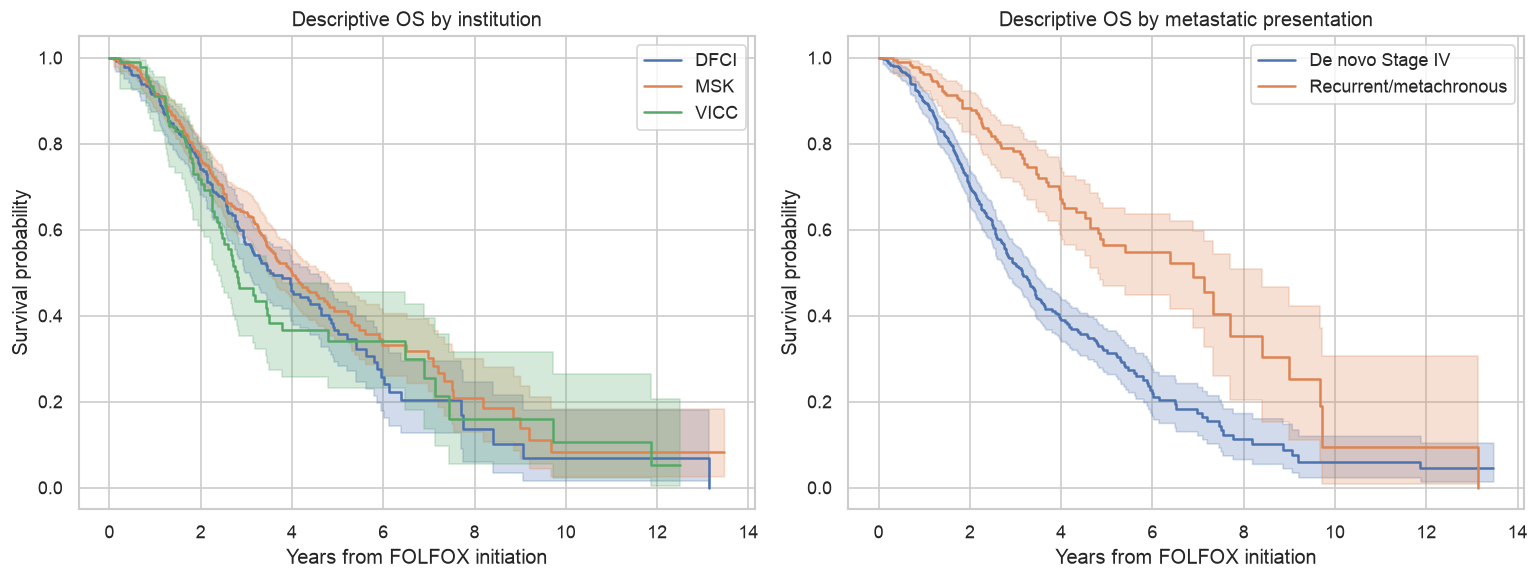

In [35]:
kmf = KaplanMeierFitter()
figure, axes = plt.subplots(1, 2, figsize=(13, 5))

for institution, group in primary_cohort.groupby("institution"):
    kmf.fit(
        group["tt_os_g_days"] / 365.25,
        event_observed=group["os_g_status"],
        label=institution,
    )
    kmf.plot_survival_function(ax=axes[0], ci_show=True)

for presentation, group in primary_cohort.groupby("metastatic_presentation"):
    kmf.fit(
        group["tt_os_g_days"] / 365.25,
        event_observed=group["os_g_status"],
        label=presentation,
    )
    kmf.plot_survival_function(ax=axes[1], ci_show=True)

axes[0].set(
    title="Descriptive OS by institution",
    xlabel="Years from FOLFOX initiation",
    ylabel="Survival probability",
)
axes[1].set(
    title="Descriptive OS by metastatic presentation",
    xlabel="Years from FOLFOX initiation",
    ylabel="Survival probability",
)
plt.tight_layout()
plt.show()

The curves are descriptive checks, not comparative causal estimates or fitted
prediction models.

## 8. Supportive endpoint: death-inclusive TTNT

The same-cancer TTNT variables are primary for this supportive endpoint. The event
is the earlier of a subsequent regimen for the same cancer or death. Any-cancer
TTNT is retained as a sensitivity definition.

In [36]:
future_same_cancer = primary_cohort[
    ["record_id", "ca_seq", "regimen_number", "regimen_origin_day"]
].merge(
    regimens[
        ["record_id", "ca_seq", "regimen_number", "regimen_origin_day"]
    ],
    on=["record_id", "ca_seq"],
    how="left",
    suffixes=("_index", "_future"),
)
future_same_cancer = future_same_cancer.loc[
    future_same_cancer["regimen_number_future"].ne(
        future_same_cancer["regimen_number_index"]
    )
    & future_same_cancer["regimen_origin_day_future"].ge(
        future_same_cancer["regimen_origin_day_index"]
    )
]
next_same_cancer_start = future_same_cancer.groupby("record_id")[
    "regimen_origin_day_future"
].min()

primary_cohort["next_same_cancer_regimen_day"] = primary_cohort["record_id"].map(
    next_same_cancer_start
)
primary_cohort["days_to_next_same_cancer_regimen"] = (
    primary_cohort["next_same_cancer_regimen_day"]
    - primary_cohort["regimen_origin_day"]
)
primary_cohort["days_to_death"] = (
    primary_cohort["hybrid_death_int"] - primary_cohort["regimen_origin_day"]
)
primary_cohort["expected_ttnt_days"] = np.where(
    primary_cohort["os_g_status"].eq(1),
    np.fmin(
        primary_cohort["days_to_next_same_cancer_regimen"],
        primary_cohort["days_to_death"],
    ),
    primary_cohort["days_to_next_same_cancer_regimen"],
)
primary_cohort["expected_ttnt_days"] = np.where(
    pd.isna(primary_cohort["expected_ttnt_days"]),
    np.where(
        primary_cohort["os_g_status"].eq(1),
        primary_cohort["days_to_death"],
        primary_cohort["dob_lastalive_int"]
        - primary_cohort["regimen_origin_day"],
    ),
    primary_cohort["expected_ttnt_days"],
)
primary_cohort["ttnt_difference_days"] = (
    primary_cohort["ttnt_ca_seq_days"] - primary_cohort["expected_ttnt_days"]
)
primary_cohort["ttnt_event_source"] = np.select(
    [
        primary_cohort["ttnt_ca_seq_status"].eq(0),
        primary_cohort["days_to_next_same_cancer_regimen"].notna()
        & (
            primary_cohort["days_to_death"].isna()
            | (
                primary_cohort["days_to_next_same_cancer_regimen"]
                <= primary_cohort["days_to_death"]
            )
        ),
    ],
    ["Censored", "Subsequent same-cancer regimen"],
    default="Death",
)

ttnt_validation = pd.DataFrame(
    [
        {
            "check": "Missing same-cancer TTNT status",
            "patients": int(primary_cohort["ttnt_ca_seq_status"].isna().sum()),
        },
        {
            "check": "Missing same-cancer TTNT time",
            "patients": int(primary_cohort["ttnt_ca_seq_days"].isna().sum()),
        },
        {
            "check": "Negative same-cancer TTNT time",
            "patients": int(primary_cohort["ttnt_ca_seq_days"].lt(0).sum()),
        },
        {
            "check": "Zero-day same-cancer TTNT event",
            "patients": int(primary_cohort["ttnt_ca_seq_days"].eq(0).sum()),
        },
        {
            "check": "Supplied TTNT differs from reconstruction",
            "patients": int(primary_cohort["ttnt_difference_days"].ne(0).sum()),
        },
        {
            "check": "Same-cancer and any-cancer TTNT time differ",
            "patients": int(
                primary_cohort["ttnt_ca_seq_days"]
                .ne(primary_cohort["ttnt_any_ca_days"])
                .sum()
            ),
        },
    ]
)
assert primary_cohort["ttnt_ca_seq_status"].isin([0, 1]).all()
assert primary_cohort["ttnt_ca_seq_days"].ge(0).all()
assert primary_cohort["ttnt_difference_days"].eq(0).all()
display(ttnt_validation)

,check,patients
0,Missing same-cancer TTNT status,0
1,Missing same-cancer TTNT time,0
2,Negative same-cancer TTNT time,0
3,Zero-day same-cancer TTNT event,2
4,Supplied TTNT differs from reconstruction,0
5,Same-cancer and any-cancer TTNT time differ,4


In [37]:
ttnt_summary = (
    primary_cohort.groupby("institution")
    .agg(
        patients=("record_id", "size"),
        ttnt_events=("ttnt_ca_seq_status", "sum"),
        event_percent=("ttnt_ca_seq_status", lambda values: 100 * values.mean()),
        median_observed_days=("ttnt_ca_seq_days", "median"),
    )
    .reset_index()
)
ttnt_event_sources = (
    primary_cohort["ttnt_event_source"]
    .value_counts()
    .rename_axis("event_source")
    .reset_index(name="patients")
)
display(ttnt_summary)
display(ttnt_event_sources)

,institution,patients,ttnt_events,event_percent,median_observed_days
0,DFCI,246,212,86.179,205.000
1,MSK,337,301,89.318,192.000
2,VICC,95,87,91.579,270.000


,event_source,patients
0,Subsequent same-cancer regimen,568
1,Censored,78
2,Death,32


## 9. Baseline clinical and longitudinal predictor availability

Availability is measured relative to FOLFOX initiation. Multiple candidate lookback
windows are described without selecting a final modeling window.

In [38]:
WINDOWS = [30, 90, 180, 365]


def source_coverage(
    cohort: pd.DataFrame,
    source: pd.DataFrame,
    time_column: str,
    source_name: str,
) -> pd.DataFrame:
    """Summarize unique-patient coverage before prediction time."""
    joined = cohort[["record_id", "institution", "regimen_origin_day"]].merge(
        source[["record_id", time_column]],
        on="record_id",
        how="left",
    )
    joined["lookback_days"] = (
        joined["regimen_origin_day"] - joined[time_column]
    )
    records = []
    for institution in ["All", *sorted(cohort["institution"].unique())]:
        cohort_subset = (
            cohort if institution == "All" else cohort[cohort["institution"].eq(institution)]
        )
        joined_subset = (
            joined
            if institution == "All"
            else joined[joined["institution"].eq(institution)]
        )
        denominator = cohort_subset["record_id"].nunique()
        for label, window in [("Any prior", None), *[(f"{w} days", w) for w in WINDOWS]]:
            eligible = joined_subset["lookback_days"].ge(0)
            if window is not None:
                eligible &= joined_subset["lookback_days"].le(window)
            patients = joined_subset.loc[eligible, "record_id"].nunique()
            records.append(
                {
                    "source": source_name,
                    "institution": institution,
                    "window": label,
                    "patients": patients,
                    "denominator": denominator,
                    "percent": 100 * patients / denominator,
                }
            )
    return pd.DataFrame(records)


cea_df = tumor_markers_df.loc[tumor_markers_df["tm_type"].eq("CEA")].copy()
coverage_summary = pd.concat(
    [
        source_coverage(
            primary_cohort,
            pathology_df,
            "path_proc_int",
            "Pathology",
        ),
        source_coverage(
            primary_cohort,
            imaging_df,
            "image_scan_int",
            "Imaging",
        ),
        source_coverage(
            primary_cohort,
            medical_oncology_df,
            "md_onc_visit_int",
            "Medical oncology",
        ),
        source_coverage(
            primary_cohort,
            cea_df,
            "tm_spec_collect_int",
            "CEA",
        ),
        source_coverage(
            primary_cohort,
            cancer_panel_tests_df,
            "dob_cpt_report_days",
            "Genomic report",
        ),
    ],
    ignore_index=True,
)

display(
    coverage_summary.loc[coverage_summary["institution"].eq("All")].pivot(
        index="source",
        columns="window",
        values=["patients", "percent"],
    )
)

patients                                     percent          \
window           180 days 30 days 365 days 90 days Any prior 180 days 30 days   
source                                                                          
CEA               408.000 377.000  409.000 405.000   409.000   60.177  55.605   
Genomic report     37.000  23.000   37.000  35.000    41.000    5.457   3.392   
Imaging           614.000 475.000  615.000 599.000   616.000   90.560  70.059   
Medical oncology  568.000 531.000  570.000 565.000   571.000   83.776  78.319   
Pathology         660.000 360.000  667.000 636.000   671.000   97.345  53.097   

                                             
window           365 days 90 days Any prior  
source                                       
CEA                60.324  59.735    60.324  
Genomic report      5.457   5.162     6.047  
Imaging            90.708  88.348    90.855  
Medical oncology   84.071  83.333    84.218  
Pathology          98.378  93.805    98.968

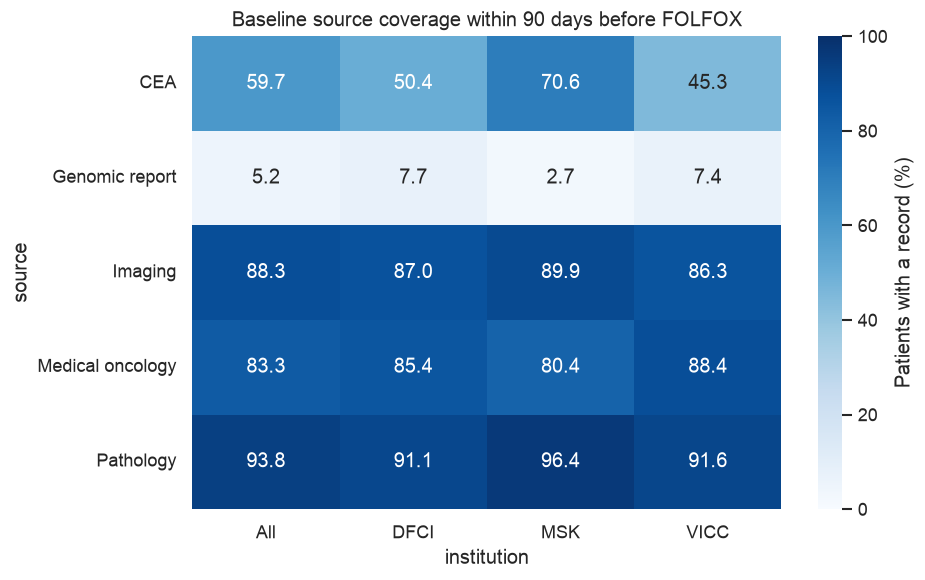

In [39]:
coverage_heatmap = coverage_summary.loc[
    coverage_summary["window"].eq("90 days")
].pivot(index="source", columns="institution", values="percent")

figure, axis = plt.subplots(figsize=(8, 5))
sns.heatmap(
    coverage_heatmap,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Patients with a record (%)"},
    ax=axis,
)
axis.set(title="Baseline source coverage within 90 days before FOLFOX")
plt.tight_layout()
plt.show()

In [41]:
primary_cohort["age_at_folfox"] = primary_cohort["age_at_regimen"]
primary_cohort["presentation"] = primary_cohort["metastatic_presentation"]

clinical_candidate_columns = [
    "age_at_folfox",
    "naaccr_sex_code",
    "race_ethnicity",
    "presentation",
    "crc_type",
    "ca_d_site",
    "ca_grade",
    "dmets_abdomen",
    "dmets_bone",
    "dmets_brain",
    "dmets_liver",
    "dmets_pelvis",
    "dmets_thorax",
    "prior_oxaliplatin",
    "biologic_with_folfox",
]

clinical_missingness_records = []
for column in clinical_candidate_columns:
    for institution in ["All", *sorted(primary_cohort["institution"].unique())]:
        group = (
            primary_cohort
            if institution == "All"
            else primary_cohort[primary_cohort["institution"].eq(institution)]
        )
        clinical_missingness_records.append(
            {
                "variable": column,
                "institution": institution,
                "missing_n": int(group[column].isna().sum()),
                "missing_percent": 100 * group[column].isna().mean(),
            }
        )

clinical_missingness = pd.DataFrame(clinical_missingness_records)
display(
    clinical_missingness.pivot(
        index="variable",
        columns="institution",
        values="missing_percent",
    )
)

institution,All,DFCI,MSK,VICC
variable,,,,
age_at_folfox,0.000,0.000,0.000,0.000
biologic_with_folfox,0.000,0.000,0.000,0.000
ca_d_site,0.000,0.000,0.000,0.000
ca_grade,15.044,26.829,8.309,8.421
crc_type,0.147,0.000,0.297,0.000
dmets_abdomen,0.000,0.000,0.000,0.000
dmets_bone,0.000,0.000,0.000,0.000
dmets_brain,0.000,0.000,0.000,0.000
dmets_liver,0.000,0.000,0.000,0.000


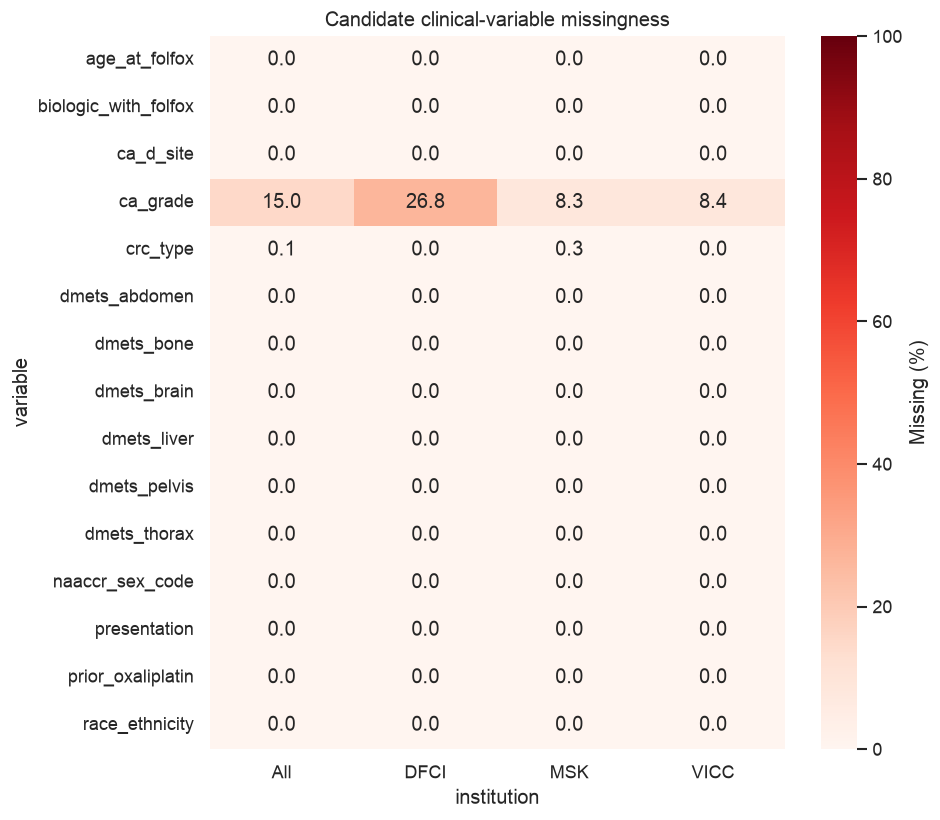

In [43]:
clinical_missingness_heatmap = clinical_missingness.pivot(
    index="variable",
    columns="institution",
    values="missing_percent",
)
figure, axis = plt.subplots(figsize=(8, 7))
sns.heatmap(
    clinical_missingness_heatmap,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Missing (%)"},
    ax=axis,
)
axis.set(title="Candidate clinical-variable missingness")
plt.tight_layout()
plt.show()

In [44]:
def closest_prior_record(
    cohort: pd.DataFrame,
    source: pd.DataFrame,
    time_column: str,
    window_days: int | None = None,
) -> pd.DataFrame:
    """Return one closest prior source row per cohort patient."""
    joined = cohort[
        ["record_id", "institution", "regimen_origin_day"]
    ].merge(
        source,
        on=["record_id", "institution"],
        how="left",
        suffixes=("", "_source"),
    )
    joined["lookback_days"] = joined["regimen_origin_day"] - joined[time_column]
    eligible = joined["lookback_days"].ge(0)
    if window_days is not None:
        eligible &= joined["lookback_days"].le(window_days)
    return (
        joined.loc[eligible]
        .sort_values(["record_id", "lookback_days"])
        .drop_duplicates("record_id")
    )


closest_imaging_90 = closest_prior_record(
    primary_cohort,
    imaging_df,
    "image_scan_int",
    90,
)
closest_medonc_90 = closest_prior_record(
    primary_cohort,
    medical_oncology_df,
    "md_onc_visit_int",
    90,
)
closest_cea_90 = closest_prior_record(
    primary_cohort,
    cea_df,
    "tm_spec_collect_int",
    90,
)

baseline_longitudinal_summaries = {
    "Closest imaging: evidence of cancer": closest_imaging_90[
        "image_ca"
    ].value_counts(dropna=False),
    "Closest imaging: overall assessment": closest_imaging_90[
        "image_overall"
    ].value_counts(dropna=False),
    "Closest medical-oncology status": closest_medonc_90[
        "md_ca_status"
    ].value_counts(dropna=False),
    "CEA units": closest_cea_90["tm_result_units"].value_counts(dropna=False),
}
for label, summary in baseline_longitudinal_summaries.items():
    print(label)
    display(summary.rename("patients").to_frame())

Closest imaging: evidence of cancer


,patients
image_ca,
"Yes, the Impression states or implies there is evidence of cancer",475
"No, the Impression states or implies there is no evidence of cancer",67
"The Impression is uncertain, indeterminate, or equivocal",51
The Impression does not mention cancer,6


Closest imaging: overall assessment


,patients
image_overall,
Not stated/Indeterminate,355
NaN,124
Progressing/Worsening/Enlarging,83
Stable/No change,31
Improving/Responding,5
Mixed,1


Closest medical-oncology status


,patients
md_ca_status,
Not stated/Indeterminate,408
NaN,101
Progressing/Worsening/Enlarging,54
Mixed,1
Stable/No change,1


CEA units


,patients
tm_result_units,
ng/mL,405


In [45]:
cea_validity = pd.DataFrame(
    [
        {
            "check": "Patients with closest prior CEA within 90 days",
            "patients": closest_cea_90["record_id"].nunique(),
        },
        {
            "check": "Missing numeric CEA result",
            "patients": int(closest_cea_90["tm_num_result"].isna().sum()),
        },
        {
            "check": "Negative numeric CEA result",
            "patients": int(closest_cea_90["tm_num_result"].lt(0).sum()),
        },
        {
            "check": "CEA unit other than ng/mL",
            "patients": int(
                closest_cea_90["tm_result_units"].notna().sum()
                - closest_cea_90["tm_result_units"].eq("ng/mL").sum()
            ),
        },
    ]
)
display(cea_validity)
display(
    closest_cea_90["tm_num_result"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .rename("closest_CEA_ng_per_mL")
    .to_frame()
)

,check,patients
0,Patients with closest prior CEA within 90 days,405
1,Missing numeric CEA result,0
2,Negative numeric CEA result,0
3,CEA unit other than ng/mL,0


,closest_CEA_ng_per_mL
count,405.000
mean,387.391
std,"1,309.825"
min,0.000
1%,0.000
5%,0.700
25%,2.900
50%,13.100
75%,121.100
95%,"2,461.980"


In [46]:
pathology_prior = primary_cohort[
    ["record_id", "institution", "regimen_origin_day"]
].merge(
    pathology_df,
    on=["record_id", "institution"],
    how="left",
)
pathology_prior["lookback_days"] = (
    pathology_prior["regimen_origin_day"] - pathology_prior["path_proc_int"]
)
pathology_prior = pathology_prior.loc[pathology_prior["lookback_days"].ge(0)].copy()

pathology_biomarker_records = []
for biomarker, testing_column, result_columns in [
    (
        "MSI",
        "msi_testing",
        ["msi_result", "msi_result_2", "msi_result_3", "msi_high_any"],
    ),
    (
        "MMR",
        "mmr_testing",
        ["mmr_result", "mmr_result_2", "mmr_result_3"],
    ),
]:
    tested_ids = set(
        pathology_prior.loc[
            pathology_prior[testing_column].eq("Yes"),
            "record_id",
        ]
    )
    result_ids = set(
        pathology_prior.loc[
            pathology_prior[result_columns].notna().any(axis=1),
            "record_id",
        ]
    )
    pathology_biomarker_records.append(
        {
            "biomarker": biomarker,
            "patients_with_pre_FOLFOX_test": len(tested_ids),
            "patients_with_pre_FOLFOX_result": len(result_ids),
            "cohort_percent_with_result": 100 * len(result_ids) / len(primary_cohort),
        }
    )

display(pd.DataFrame(pathology_biomarker_records))
display(
    pathology_prior.loc[pathology_prior["msi_result"].notna(), "msi_result"]
    .value_counts()
    .rename("pathology_reports")
    .to_frame()
)
display(
    pathology_prior.loc[pathology_prior["mmr_result"].notna(), "mmr_result"]
    .value_counts()
    .rename("pathology_reports")
    .to_frame()
)

display(
    Markdown(
        "> **Timing limitation:** the pathology table provides the procedure date, "
        "not a separate biomarker-result date. Procedure date is therefore only a "
        "proxy for when MSI/MMR information became clinically available."
    )
)

,biomarker,patients_with_pre_FOLFOX_test,patients_with_pre_FOLFOX_result,cohort_percent_with_result
0,MSI,120,120,17.699
1,MMR,453,453,66.814


,pathology_reports
msi_result,
MSS: STABLE,109
MSI-L: LOW or instability in < 30% of microsatellite markers,9
MSI-H: HIGH,6


,pathology_reports
mmr_result,
No loss of nuclear expression of MMR proteins: No evidence of deficient mismatch repair (low probability of MSI-H): proficient,467
Loss of nuclear expression of one or more MMR proteins; deficient mismatch repair,22
Indeterminate/Not stated,8


> **Timing limitation:** the pathology table provides the procedure date, not a separate biomarker-result date. Procedure date is therefore only a proxy for when MSI/MMR information became clinically available.

## 10. Baseline genomic feasibility

A genomic result is considered available only when its cancer-panel report date is
at or before FOLFOX initiation and it is associated with the qualifying cancer.
A specimen collected earlier but reported later is not treated as a baseline
predictor.

In [47]:
cpt_relative = primary_cohort[
    [
        "record_id",
        "institution",
        "ca_seq",
        "regimen_origin_day",
        "os_g_status",
    ]
].merge(
    cancer_panel_tests_df,
    on=["record_id", "institution", "ca_seq"],
    how="left",
    suffixes=("", "_cpt"),
)
cpt_relative["cpt_lag_from_folfox_days"] = (
    cpt_relative["dob_cpt_report_days"] - cpt_relative["regimen_origin_day"]
)
cpt_relative["baseline_report"] = cpt_relative[
    "cpt_lag_from_folfox_days"
].le(0)

baseline_cpt_all = cpt_relative.loc[cpt_relative["baseline_report"]].copy()
baseline_cpt = (
    baseline_cpt_all.sort_values(
        ["record_id", "dob_cpt_report_days", "cpt_number"],
        ascending=[True, False, False],
    )
    .drop_duplicates("record_id")
    .copy()
)
first_cpt_lag = (
    cpt_relative.groupby(["record_id", "institution"], as_index=False)
    .agg(first_cpt_lag_days=("cpt_lag_from_folfox_days", "min"))
)

genomic_timing_summary = (
    primary_cohort.groupby("institution")
    .agg(cohort_patients=("record_id", "size"))
    .join(
        baseline_cpt.groupby("institution")["record_id"]
        .nunique()
        .rename("baseline_genomic_patients"),
        how="left",
    )
    .fillna(0)
    .reset_index()
)
genomic_timing_summary["baseline_percent"] = (
    100
    * genomic_timing_summary["baseline_genomic_patients"]
    / genomic_timing_summary["cohort_patients"]
)
genomic_timing_summary["baseline_genomic_patients"] = genomic_timing_summary[
    "baseline_genomic_patients"
].astype(int)
display(genomic_timing_summary)

,institution,cohort_patients,baseline_genomic_patients,baseline_percent
0,DFCI,246,23,9.350
1,MSK,337,11,3.264
2,VICC,95,7,7.368


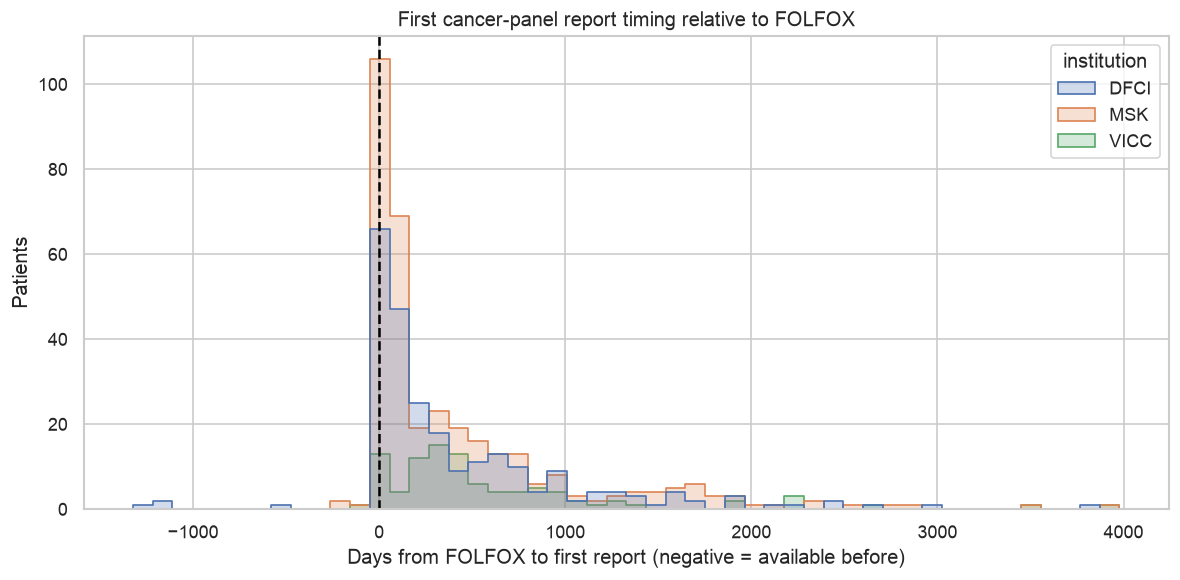

In [48]:
figure, axis = plt.subplots(figsize=(10, 5))
sns.histplot(
    data=first_cpt_lag,
    x="first_cpt_lag_days",
    hue="institution",
    bins=50,
    element="step",
    common_norm=False,
    ax=axis,
)
axis.axvline(0, color="black", linestyle="--", label="FOLFOX initiation")
axis.set(
    title="First cancer-panel report timing relative to FOLFOX",
    xlabel="Days from FOLFOX to first report (negative = available before)",
    ylabel="Patients",
)
plt.tight_layout()
plt.show()

In [49]:
mutations_df = pd.read_csv(
    DATA_DIR / "data_mutations_extended.txt",
    sep="\t",
    comment="#",
    low_memory=False,
)
fusions_df = pd.read_csv(
    DATA_DIR / "data_fusions.txt",
    sep="\t",
    comment="#",
    low_memory=False,
)
tmb_df = pd.read_csv(DATA_DIR / "tmb.tsv", sep="\t", low_memory=False)
gene_matrix_df = pd.read_csv(
    DATA_DIR / "data_gene_matrix.txt",
    sep="\t",
    low_memory=False,
)
cna_df = pd.read_csv(
    DATA_DIR / "data_CNA.txt",
    sep="\t",
    low_memory=False,
)

baseline_sample_ids = set(
    baseline_cpt_all["cpt_genie_sample_id"].dropna().astype(str)
)
genomic_linkage = pd.DataFrame(
    [
        {
            "genomic_source": "Cancer-panel analytic table",
            "eligible_baseline_samples": len(baseline_sample_ids),
            "linked_samples": len(baseline_sample_ids),
        },
        {
            "genomic_source": "Mutation file",
            "eligible_baseline_samples": len(baseline_sample_ids),
            "linked_samples": len(
                baseline_sample_ids
                & set(mutations_df["Tumor_Sample_Barcode"].astype(str))
            ),
        },
        {
            "genomic_source": "CNA matrix",
            "eligible_baseline_samples": len(baseline_sample_ids),
            "linked_samples": len(baseline_sample_ids & set(cna_df.columns[1:])),
        },
        {
            "genomic_source": "Fusion file (positive records only)",
            "eligible_baseline_samples": len(baseline_sample_ids),
            "linked_samples": len(
                baseline_sample_ids
                & set(fusions_df["Tumor_Sample_Barcode"].astype(str))
            ),
        },
        {
            "genomic_source": "TMB file",
            "eligible_baseline_samples": len(baseline_sample_ids),
            "linked_samples": len(
                baseline_sample_ids & set(tmb_df["SAMPLE_ID"].astype(str))
            ),
        },
        {
            "genomic_source": "Gene-matrix assay mapping",
            "eligible_baseline_samples": len(baseline_sample_ids),
            "linked_samples": len(
                baseline_sample_ids & set(gene_matrix_df["SAMPLE_ID"].astype(str))
            ),
        },
    ]
)
genomic_linkage["linked_percent"] = (
    100
    * genomic_linkage["linked_samples"]
    / genomic_linkage["eligible_baseline_samples"].replace(0, np.nan)
)
display(genomic_linkage)

,genomic_source,eligible_baseline_samples,linked_samples,linked_percent
0,Cancer-panel analytic table,42,42,100.000
1,Mutation file,42,42,100.000
2,CNA matrix,42,36,85.714
3,Fusion file (positive records only),42,5,11.905
4,TMB file,42,42,100.000
5,Gene-matrix assay mapping,42,42,100.000


In [50]:
baseline_mutations = mutations_df.loc[
    mutations_df["Tumor_Sample_Barcode"].astype(str).isin(baseline_sample_ids)
].copy()
top_baseline_mutation_genes = (
    baseline_mutations.groupby("Hugo_Symbol")["Tumor_Sample_Barcode"]
    .nunique()
    .sort_values(ascending=False)
    .head(20)
    .rename("altered_baseline_samples")
    .to_frame()
)
display(top_baseline_mutation_genes)

baseline_cna_columns = [
    column for column in cna_df.columns[1:] if column in baseline_sample_ids
]
baseline_cna = cna_df[["Hugo_Symbol", *baseline_cna_columns]].copy()
baseline_cna["altered_baseline_samples"] = (
    baseline_cna[baseline_cna_columns].fillna(0).ne(0).sum(axis=1)
)
display(
    baseline_cna.nlargest(20, "altered_baseline_samples")[
        ["Hugo_Symbol", "altered_baseline_samples"]
    ].set_index("Hugo_Symbol")
)

baseline_fusions = fusions_df.loc[
    fusions_df["Tumor_Sample_Barcode"].astype(str).isin(baseline_sample_ids)
]
display(
    baseline_fusions["Hugo_Symbol"]
    .value_counts()
    .head(20)
    .rename("positive_fusion_records")
    .to_frame()
)

,altered_baseline_samples
Hugo_Symbol,
TP53,29
APC,26
KRAS,21
PIK3CA,8
PTEN,7
ARID1B,6
EP300,6
SOX9,6
PALB2,5


,altered_baseline_samples
Hugo_Symbol,
ASXL1,15
AURKA,15
FLT3,15
BCL2L1,14
GNAS,14
SMAD4,14
ZNF217,14
BRCA2,13
FLT1,13


,positive_fusion_records
Hugo_Symbol,
FOXO1,2
CTNNB1,1
POLG,1
UNC5D,1
WHSC1L1,1
FBXO11,1


In [51]:
baseline_tmb = tmb_df.loc[
    tmb_df["SAMPLE_ID"].astype(str).isin(baseline_sample_ids)
].copy()
baseline_tmb["tmb_per_mb"] = baseline_tmb["tmb"] * 1_000_000
display(
    baseline_tmb[["tmb_per_mb"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .T
)
display(
    baseline_tmb["tmb_bin"]
    .value_counts(dropna=False)
    .rename("baseline_samples")
    .to_frame()
)

,count,mean,std,min,25%,50%,75%,90%,95%,max
tmb_per_mb,42.000,14.228,21.169,0.000,4.190,6.317,9.404,51.423,51.978,103.956


,baseline_samples
tmb_bin,
Mid (2-16),32
High (>16),7
Low (<2),3


In [52]:
def read_panel_genes(file_path: Path) -> set[str]:
    """Parse the tab-separated gene list from a cBioPortal panel definition."""
    with file_path.open(encoding="utf-8") as file_handle:
        for line in file_handle:
            if line.startswith("gene_list:"):
                return set(line.rstrip("\n").split("\t")[1:])
    return set()


panel_files = sorted(DATA_DIR.glob("data_gene_panel_*.txt"))
panel_gene_sets = {
    file_path.stem.removeprefix("data_gene_panel_"): read_panel_genes(file_path)
    for file_path in panel_files
}
panel_summary = pd.DataFrame(
    [
        {"assay": assay, "covered_genes": len(genes)}
        for assay, genes in panel_gene_sets.items()
    ]
).sort_values("assay", ignore_index=True)
display(panel_summary)

core_crc_genes = [
    "APC",
    "BRAF",
    "FBXW7",
    "KRAS",
    "NRAS",
    "PIK3CA",
    "SMAD4",
    "TP53",
]
baseline_assay_counts = baseline_cpt_all[
    "cpt_seq_assay_id"
].value_counts()
panel_coverage_records = []
for gene in core_crc_genes:
    covered_samples = sum(
        count
        for assay, count in baseline_assay_counts.items()
        if gene in panel_gene_sets.get(str(assay), set())
    )
    panel_coverage_records.append(
        {
            "gene": gene,
            "baseline_samples": len(baseline_cpt_all),
            "samples_on_panel_covering_gene": int(covered_samples),
            "coverage_percent": (
                100 * covered_samples / len(baseline_cpt_all)
                if len(baseline_cpt_all)
                else np.nan
            ),
        }
    )
display(pd.DataFrame(panel_coverage_records).set_index("gene"))

,assay,covered_genes
0,DFCI-ONCOPANEL-2,326
1,DFCI-ONCOPANEL-3,447
2,MSK-IMPACT341,341
3,MSK-IMPACT410,410
4,MSK-IMPACT468,468
5,VICC-01-SOLIDTUMOR,31
6,VICC-01-T5A,323
7,VICC-01-T7,429


,baseline_samples,samples_on_panel_covering_gene,coverage_percent
gene,,,
APC,42,36,85.714
BRAF,42,42,100.000
FBXW7,42,36,85.714
KRAS,42,42,100.000
NRAS,42,42,100.000
PIK3CA,42,42,100.000
SMAD4,42,36,85.714
TP53,42,42,100.000


In [53]:
mutation_samples_by_gene = (
    baseline_mutations.groupby("Hugo_Symbol")["Tumor_Sample_Barcode"]
    .apply(set)
    .to_dict()
)
baseline_status_records = []
for gene in core_crc_genes:
    positive_samples = mutation_samples_by_gene.get(gene, set())
    covered_sample_ids = set(
        baseline_cpt_all.loc[
            baseline_cpt_all["cpt_seq_assay_id"].map(
                lambda assay, target_gene=gene: target_gene
                in panel_gene_sets.get(str(assay), set())
            ),
            "cpt_genie_sample_id",
        ].astype(str)
    )
    positive_patients = baseline_cpt_all.loc[
        baseline_cpt_all["cpt_genie_sample_id"].astype(str).isin(positive_samples),
        "record_id",
    ].nunique()
    covered_negative_patients = baseline_cpt_all.loc[
        baseline_cpt_all["cpt_genie_sample_id"].astype(str).isin(
            covered_sample_ids - positive_samples
        ),
        "record_id",
    ].nunique()
    not_covered_patients = baseline_cpt_all.loc[
        ~baseline_cpt_all["cpt_genie_sample_id"].astype(str).isin(
            covered_sample_ids
        ),
        "record_id",
    ].nunique()
    baseline_status_records.append(
        {
            "gene": gene,
            "altered": positive_patients,
            "tested_negative": covered_negative_patients,
            "not_covered": not_covered_patients,
            "no_pre_FOLFOX_genomic_report": (
                len(primary_cohort) - baseline_cpt["record_id"].nunique()
            ),
        }
    )
display(pd.DataFrame(baseline_status_records).set_index("gene"))

,altered,tested_negative,not_covered,no_pre_FOLFOX_genomic_report
gene,,,,
APC,26,10,6,637
BRAF,2,39,0,637
FBXW7,5,31,6,637
KRAS,20,21,0,637
NRAS,2,39,0,637
PIK3CA,8,33,0,637
SMAD4,5,31,6,637
TP53,29,12,0,637


A fusion file contains positive fusion records rather than explicit negatives.
Absence from that file must therefore be combined with assay coverage metadata
before being interpreted as a tested-negative feature.

## 11. Sample-size, missingness, and institutional transportability

In [54]:
institution_event_support = (
    primary_cohort.groupby("institution")
    .agg(
        held_out_patients=("record_id", "size"),
        held_out_os_events=("os_g_status", "sum"),
        held_out_ttnt_events=("ttnt_ca_seq_status", "sum"),
    )
    .reset_index()
)
total_patients = len(primary_cohort)
total_os_events = int(primary_cohort["os_g_status"].sum())
total_ttnt_events = int(primary_cohort["ttnt_ca_seq_status"].sum())
institution_event_support["training_patients"] = (
    total_patients - institution_event_support["held_out_patients"]
)
institution_event_support["training_os_events"] = (
    total_os_events - institution_event_support["held_out_os_events"]
)
institution_event_support["training_ttnt_events"] = (
    total_ttnt_events - institution_event_support["held_out_ttnt_events"]
)
display(institution_event_support)

,institution,held_out_patients,held_out_os_events,held_out_ttnt_events,training_patients,training_os_events,training_ttnt_events
0,DFCI,246,141,212,432,236,388
1,MSK,337,179,301,341,198,299
2,VICC,95,57,87,583,320,513


In [55]:
core_complete = primary_cohort[clinical_candidate_columns].notna().all(axis=1)
cea_90_ids = set(closest_cea_90["record_id"])
msi_result_ids = set(
    pathology_prior.loc[
        pathology_prior[
            ["msi_result", "msi_result_2", "msi_result_3", "msi_high_any"]
        ].notna().any(axis=1),
        "record_id",
    ]
)
mmr_result_ids = set(
    pathology_prior.loc[
        pathology_prior[
            ["mmr_result", "mmr_result_2", "mmr_result_3"]
        ].notna().any(axis=1),
        "record_id",
    ]
)
baseline_genomic_ids = set(baseline_cpt["record_id"])


def feature_set_support(
    name: str,
    patient_mask: pd.Series,
    illustrative_dimensions: int,
) -> dict[str, object]:
    group = primary_cohort.loc[patient_mask]
    events = int(group["os_g_status"].sum())
    return {
        "candidate_feature_set": name,
        "patients": len(group),
        "os_events": events,
        "illustrative_candidate_dimensions": illustrative_dimensions,
        "events_per_candidate_dimension": (
            events / illustrative_dimensions if illustrative_dimensions else np.nan
        ),
    }


feature_support = pd.DataFrame(
    [
        feature_set_support(
            "Core clinical complete case",
            core_complete,
            len(clinical_candidate_columns),
        ),
        feature_set_support(
            "Core clinical + CEA within 90 days",
            core_complete & primary_cohort["record_id"].isin(cea_90_ids),
            len(clinical_candidate_columns) + 1,
        ),
        feature_set_support(
            "Core clinical + documented MSI/MMR result",
            core_complete
            & primary_cohort["record_id"].isin(msi_result_ids | mmr_result_ids),
            len(clinical_candidate_columns) + 1,
        ),
        feature_set_support(
            "Baseline genomic",
            primary_cohort["record_id"].isin(baseline_genomic_ids),
            len(core_crc_genes),
        ),
        feature_set_support(
            "Combined core clinical + baseline genomic",
            core_complete
            & primary_cohort["record_id"].isin(baseline_genomic_ids),
            len(clinical_candidate_columns) + len(core_crc_genes),
        ),
    ]
)
display(feature_support)

,candidate_feature_set,patients,os_events,illustrative_candidate_dimensions,events_per_candidate_dimension
0,Core clinical complete case,575,307,15,20.467
1,Core clinical + CEA within 90 days,356,187,16,11.688
2,Core clinical + documented MSI/MMR result,424,219,16,13.688
3,Baseline genomic,41,11,8,1.375
4,Combined core clinical + baseline genomic,38,10,23,0.435


The dimension counts above are illustrative audit denominators, not a feature
selection decision or a rule that events-per-variable alone establishes model
validity.

In [56]:
categorical_heterogeneity_records = []
for variable in [
    "naaccr_sex_code",
    "race_ethnicity",
    "presentation",
    "crc_type",
    "ca_grade",
    "prior_oxaliplatin",
    "biologic_with_folfox",
]:
    counts = (
        primary_cohort.groupby(["institution", variable], dropna=False)
        .size()
        .rename("patients")
        .reset_index()
    )
    counts["within_institution_percent"] = counts.groupby("institution")[
        "patients"
    ].transform(lambda values: 100 * values / values.sum())
    counts.insert(0, "variable", variable)
    counts = counts.rename(columns={variable: "category"})
    categorical_heterogeneity_records.append(
        counts[
            [
                "variable",
                "institution",
                "category",
                "patients",
                "within_institution_percent",
            ]
        ]
    )

categorical_heterogeneity = pd.concat(
    categorical_heterogeneity_records,
    ignore_index=True,
)
rare_center_categories = categorical_heterogeneity.loc[
    categorical_heterogeneity["patients"] < 10
].sort_values(["variable", "institution", "patients"])
display(rare_center_categories)

,variable,institution,category,patients,within_institution_percent
41,ca_grade,DFCI,I,9,3.659
49,ca_grade,MSK,IV,3,0.890
46,ca_grade,MSK,I,5,1.484
51,ca_grade,VICC,I,4,4.211
54,ca_grade,VICC,NaN,8,8.421
36,crc_type,MSK,NaN,1,0.297
38,crc_type,VICC,Other,4,4.211
56,prior_oxaliplatin,DFCI,True,8,3.252
58,prior_oxaliplatin,MSK,True,8,2.374
60,prior_oxaliplatin,VICC,True,3,3.158


## 12. Leakage, selection-bias, and design audit

In [57]:
baseline_genomic_n = baseline_cpt["record_id"].nunique()
baseline_genomic_by_center = (
    baseline_cpt.groupby("institution")["record_id"].nunique()
)
smallest_center_n = int(
    institution_event_support["held_out_patients"].min()
)
smallest_center_os_events = int(
    institution_event_support["held_out_os_events"].min()
)

design_audit = pd.DataFrame(
    [
        {
            "issue": "Post-prediction clinical records",
            "finding": "Excluded by record-level time comparisons",
            "assessment": "PASS",
        },
        {
            "issue": "Outcome leakage",
            "finding": "Outcome and future-treatment fields are used only for endpoint validation",
            "assessment": "PASS",
        },
        {
            "issue": "Post-FOLFOX genomic reports",
            "finding": (
                f"Excluded; only {baseline_genomic_n}/{len(primary_cohort)} patients "
                "have a report available by FOLFOX"
            ),
            "assessment": "HIGH RISK",
        },
        {
            "issue": "Delayed study entry / sequencing selection",
            "finding": (
                "Release eligibility required later genomic sequencing; patients whose "
                "FOLFOX predates sequencing were selected conditional on surviving and "
                "remaining observable until sequencing"
            ),
            "assessment": "HIGH RISK",
        },
        {
            "issue": "Pathology biomarker timing",
            "finding": "Procedure date is available but a distinct result-return date is not",
            "assessment": "LIMITATION",
        },
        {
            "issue": "Longitudinal curation start",
            "finding": (
                "PRISSMM records generally begin around the first BPC cancer diagnosis; "
                "earlier history may be incomplete"
            ),
            "assessment": "LIMITATION",
        },
        {
            "issue": "Routine labs and performance status",
            "finding": "Not available as a general baseline laboratory/ECOG dataset",
            "assessment": "LIMITATION",
        },
        {
            "issue": "Center transportability",
            "finding": (
                f"All three centers are represented, but the smallest held-out center has "
                f"{smallest_center_n} patients and {smallest_center_os_events} OS events"
            ),
            "assessment": "CAUTION",
        },
    ]
)
display(design_audit)

,issue,finding,assessment
0,Post-prediction clinical records,Excluded by record-level time comparisons,PASS
1,Outcome leakage,Outcome and future-treatment fields are used only for endpoint validation,PASS
2,Post-FOLFOX genomic reports,Excluded; only 41/678 patients have a report available by FOLFOX,HIGH RISK
3,Delayed study entry / sequencing selection,Release eligibility required later genomic sequencing; patients whose FOLFOX predates sequencing were selected conditional on surviving ...,HIGH RISK
4,Pathology biomarker timing,Procedure date is available but a distinct result-return date is not,LIMITATION
5,Longitudinal curation start,PRISSMM records generally begin around the first BPC cancer diagnosis; earlier history may be incomplete,LIMITATION
6,Routine labs and performance status,Not available as a general baseline laboratory/ECOG dataset,LIMITATION
7,Center transportability,"All three centers are represented, but the smallest held-out center has 95 patients and 57 OS events",CAUTION


## 13. Feasibility decision

In [60]:
clinical_os_status = (
    "GREEN"
    if len(primary_cohort) >= 500
    and total_os_events >= 300
    and primary_cohort["tt_os_g_days"].notna().all()
    else "AMBER"
)
ttnt_status = (
    "GREEN"
    if primary_cohort["ttnt_ca_seq_days"].notna().all()
    and primary_cohort["ttnt_difference_days"].eq(0).all()
    else "AMBER"
)
genomic_status = (
    "GREEN"
    if baseline_genomic_n >= 300
    and baseline_genomic_by_center.reindex(
        primary_cohort["institution"].unique(),
        fill_value=0,
    ).min()
    >= 50
    else "RED"
)
iecv_status = (
    "GREEN"
    if smallest_center_n >= 150 and smallest_center_os_events >= 75
    else "AMBER"
)

feasibility_decision = pd.DataFrame(
    [
        {
            "component": "Clinical OS endpoint and cohort",
            "status": clinical_os_status,
            "evidence": (
                f"{len(primary_cohort)} patients, {total_os_events} deaths, "
                "complete and exactly reproducible regimen-level OS"
            ),
            "decision": (
                "Statistically supportable for focused clinical prognostic development, "
                "subject to addressing sequencing-based delayed entry."
            ),
        },
        {
            "component": "Death-inclusive same-cancer TTNT",
            "status": ttnt_status,
            "evidence": (
                f"{total_ttnt_events} events; supplied values exactly reconstructed; "
                f"{int(primary_cohort['ttnt_ca_seq_days'].eq(0).sum())} zero-day events"
            ),
            "decision": (
                "Usable as a supportive endpoint after prespecifying the zero-day and "
                "same-cancer rules; do not label it a validated progression surrogate."
            ),
        },
        {
            "component": "Baseline genomic feature set",
            "status": genomic_status,
            "evidence": (
                f"{baseline_genomic_n}/{len(primary_cohort)} patients have a same-cancer "
                "genomic report available by FOLFOX"
            ),
            "decision": (
                "Not feasible as the proposed primary baseline feature set or for "
                "three-center IECV under the current prediction-time definition."
            ),
        },
        {
            "component": "Combined clinical-genomic model",
            "status": genomic_status,
            "evidence": (
                "Combined analysis is limited to the small pre-FOLFOX genomic subset"
            ),
            "decision": (
                "Do not proceed as a main model; any analysis would be exploratory and "
                "unable to support the planned cross-center comparison."
            ),
        },
        {
            "component": "Institution-level internal-external validation",
            "status": iecv_status,
            "evidence": (
                f"Smallest held-out center: {smallest_center_n} patients and "
                f"{smallest_center_os_events} deaths"
            ),
            "decision": (
                "Possible for a parsimonious clinical model, but center-specific "
                "uncertainty and missingness heterogeneity must be reported."
            ),
        },
        {
            "component": "Broad comparison of complex survival algorithms",
            "status": "AMBER",
            "evidence": (
                "Clinical event support is reasonable, but effective sample sizes fall "
                "after adding sparse longitudinal features and within IECV folds"
            ),
            "decision": (
                "Freeze a small feature set first and limit methods/tuning complexity; "
                "avoid a large model zoo."
            ),
        },
    ]
)
display(feasibility_decision)

,component,status,evidence,decision
0,Clinical OS endpoint and cohort,GREEN,"678 patients, 377 deaths, complete and exactly reproducible regimen-level OS","Statistically supportable for focused clinical prognostic development, subject to addressing sequencing-based delayed entry."
1,Death-inclusive same-cancer TTNT,GREEN,600 events; supplied values exactly reconstructed; 2 zero-day events,Usable as a supportive endpoint after prespecifying the zero-day and same-cancer rules; do not label it a validated progression surrogate.
2,Baseline genomic feature set,RED,41/678 patients have a same-cancer genomic report available by FOLFOX,Not feasible as the proposed primary baseline feature set or for three-center IECV under the current prediction-time definition.
3,Combined clinical-genomic model,RED,Combined analysis is limited to the small pre-FOLFOX genomic subset,Do not proceed as a main model; any analysis would be exploratory and unable to support the planned cross-center comparison.
4,Institution-level internal-external validation,AMBER,Smallest held-out center: 95 patients and 57 deaths,"Possible for a parsimonious clinical model, but center-specific uncertainty and missingness heterogeneity must be reported."
5,Broad comparison of complex survival algorithms,AMBER,"Clinical event support is reasonable, but effective sample sizes fall after adding sparse longitudinal features and within IECV folds",Freeze a small feature set first and limit methods/tuning complexity; avoid a large model zoo.


In [61]:
display(
    Markdown(
        f"""
### Evidence-based conclusion

The **clinical portion is feasible with important design qualifications**:
the primary definition identifies **{len(primary_cohort):,} adults** across all
three institutions with **{total_os_events:,} deaths** and complete, internally
consistent OS. Same-cancer TTNT-D is also complete and exactly reconstructable.

The **genomic portion is not feasible as written at FOLFOX initiation**. Only
**{baseline_genomic_n:,} patients** have a same-cancer sequencing report available
by prediction time. Using later reports would introduce direct temporal leakage,
and restricting to the baseline-genomic subset would be too small for the planned
three-center internal-external validation.

The most defensible next step is therefore to:

1. develop a parsimonious **clinical/non-genomic prognostic model** from FOLFOX
   initiation;
2. explicitly address the guide-described sequencing-selection and delayed-entry
   problem in the design and interpretation;
3. retain TTNT-D as a supportive, treatment-practice-sensitive endpoint; and
4. omit the combined genomic comparison unless the prediction time is changed to
   sequencing-result availability or a different dataset supplies genuinely
   pre-treatment genomic results.

Changing the prediction time to sequencing would answer a different clinical
question and must be treated as a protocol revision, not a sensitivity analysis.
"""
    )
)


### Evidence-based conclusion

The **clinical portion is feasible with important design qualifications**:
the primary definition identifies **678 adults** across all
three institutions with **377 deaths** and complete, internally
consistent OS. Same-cancer TTNT-D is also complete and exactly reconstructable.

The **genomic portion is not feasible as written at FOLFOX initiation**. Only
**41 patients** have a same-cancer sequencing report available
by prediction time. Using later reports would introduce direct temporal leakage,
and restricting to the baseline-genomic subset would be too small for the planned
three-center internal-external validation.

The most defensible next step is therefore to:

1. develop a parsimonious **clinical/non-genomic prognostic model** from FOLFOX
   initiation;
2. explicitly address the guide-described sequencing-selection and delayed-entry
   problem in the design and interpretation;
3. retain TTNT-D as a supportive, treatment-practice-sensitive endpoint; and
4. omit the combined genomic comparison unless the prediction time is changed to
   sequencing-result availability or a different dataset supplies genuinely
   pre-treatment genomic results.

Changing the prediction time to sequencing would answer a different clinical
question and must be treated as a protocol revision, not a sensitivity analysis.


## 14. Final executable assertions

These checks are intentionally strict. If a later data release changes the schema
or cohort logic, the notebook should fail visibly rather than silently producing a
different analysis population.

In [62]:
final_assertions = {
    "59 local release files": len(file_inventory) == 59,
    "58 manifest payloads": len(manifest_df) == 58,
    "all manifest hashes present": manifest_hashes.issubset(local_hashes),
    "nine analytic tables loaded": len(tables) == 9,
    "patient key unique": patient_df["record_id"].is_unique,
    "no orphan patient IDs": (
        linkage_audit["patient_ids_not_in_patient_table"].sum() == 0
    ),
    "no institution mismatches": (
        linkage_audit["institution_disagreements"].sum() == 0
    ),
    "one primary-cohort row per patient": primary_cohort["record_id"].is_unique,
    "all cohort members are adults": primary_cohort["age_at_regimen"].ge(18).all(),
    "all qualifying regimens begin after metastatic presentation": (
        primary_cohort["regimen_origin_day"]
        .ge(primary_cohort["advanced_origin_day"])
        .all()
    ),
    "all qualifying regimens contain FOLFOX backbone": primary_cohort[
        "drug_set"
    ].map(FOLFOX_BACKBONE.issubset).all(),
    "no CAPOX/FOLFOXIRI in primary cohort": ~primary_cohort["drug_set"].map(
        lambda drugs: contains_drug(drugs, "capecitabine")
        or contains_drug(drugs, "irinotecan")
    ).any(),
    "OS complete and nonnegative": (
        primary_cohort[["os_g_status", "tt_os_g_days"]].notna().all().all()
        and primary_cohort["tt_os_g_days"].ge(0).all()
    ),
    "OS exactly reconstructed": primary_cohort["os_difference_days"].eq(0).all(),
    "TTNT complete and nonnegative": (
        primary_cohort[
            ["ttnt_ca_seq_status", "ttnt_ca_seq_days"]
        ].notna().all().all()
        and primary_cohort["ttnt_ca_seq_days"].ge(0).all()
    ),
    "TTNT exactly reconstructed": primary_cohort[
        "ttnt_difference_days"
    ].eq(0).all(),
    "baseline genomic reports do not occur after FOLFOX": baseline_cpt_all[
        "cpt_lag_from_folfox_days"
    ].le(0).all(),
}

assertion_results = pd.DataFrame(
    [
        {"assertion": assertion, "passed": bool(passed)}
        for assertion, passed in final_assertions.items()
    ]
)
assert assertion_results["passed"].all(), assertion_results.loc[
    ~assertion_results["passed"]
]
display(assertion_results)
print("All feasibility-EDA assertions passed.")

,assertion,passed
0,59 local release files,True
1,58 manifest payloads,True
2,all manifest hashes present,True
3,nine analytic tables loaded,True
4,patient key unique,True
5,no orphan patient IDs,True
6,no institution mismatches,True
7,one primary-cohort row per patient,True
8,all cohort members are adults,True
9,all qualifying regimens begin after metastatic presentation,True


All feasibility-EDA assertions passed.


## Appendix A. Complete local release inventory

This appendix confirms that every local file was considered. Deep analytical work
is concentrated on files relevant to cohort construction, predictors, endpoints,
genomic linkage, or their metadata.

In [63]:
display(
    file_inventory[
        [
            "file",
            "role",
            "extension",
            "size_mb",
            "manifest_match_method",
            "size_matches_manifest",
            "hash_matches_manifest",
        ]
    ].sort_values(["role", "file"], ignore_index=True)
)

,file,role,extension,size_mb,manifest_match_method,size_matches_manifest,hash_matches_manifest
0,cases_Colorectal_Cancer.txt,case list,.txt,0.039,name,True,True
1,cases_all.txt,case list,.txt,0.039,name,True,True
2,cases_cna.txt,case list,.txt,0.037,name,True,True
3,cases_cnaseq.txt,case list,.txt,0.037,name,True,True
4,cases_sequenced.txt,case list,.txt,0.039,name,True,True
5,BPC_CRC_v2.0-public_variable_synopsis.xlsx,documentation,.xlsx,0.148,name,True,True
6,GENIE BPC CRC v2.0-public Analytic Data Guide v5.pdf,documentation,.pdf,1.173,md5,True,True
7,data_gene_panel_DFCI-ONCOPANEL-2.txt,gene-panel definition,.txt,0.002,name,True,True
8,data_gene_panel_DFCI-ONCOPANEL-3.txt,gene-panel definition,.txt,0.003,name,True,True
9,data_gene_panel_MSK-IMPACT341.txt,gene-panel definition,.txt,0.002,name,True,True


## Appendix B. All analytic fields

## Appendix C. Interpretation boundaries

- This cohort is conditional on receiving FOLFOX and does not estimate causal
  treatment benefit.
- GENIE BPC is a sequenced academic-center cohort; results do not imply universal
  external validity.
- No predictor feature set, preprocessing recipe, model, or tuning plan has been
  selected here.
- The feasibility conclusions should be converted into a prespecified modeling
  protocol before any comparative model evaluation.